In [1]:
!pip install rasterio matplotlib numpy torch torchvision

In [1]:
import os
import rasterio
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
s1_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand"
label_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand"

image_name = "Bolivia_103757_S1Hand.tif"
label_name = "Bolivia_103757_LabelHand.tif"

image_path = os.path.join(s1_folder, image_name)
label_path = os.path.join(label_folder, label_name)

len(image_name)

25

In [3]:
### dataset info
with rasterio.open(image_path) as src:
    print("file:",image_name[0])
    print("width:",src.width)
    print("height:",src.height)
    print("no.of bands:",src.count)
    print("data type:",src.dtypes)
    
    
    image = src.read()
    print("Image shape:", image.shape)
    print("Minimum value:", image.min())
    print("Maximum value:", image.max())
    for i in range(src.count):
        print(f"Band {i+1}:")
        print("  Min:", image[i].min())
        print("  Max:", image[i].max())
        print("  Mean:", image[i].mean())

file: B
width: 512
height: 512
no.of bands: 2
data type: ('float32', 'float32')
Image shape: (2, 512, 512)
Minimum value: nan
Maximum value: nan
Band 1:
  Min: nan
  Max: nan
  Mean: nan
Band 2:
  Min: nan
  Max: nan
  Mean: nan


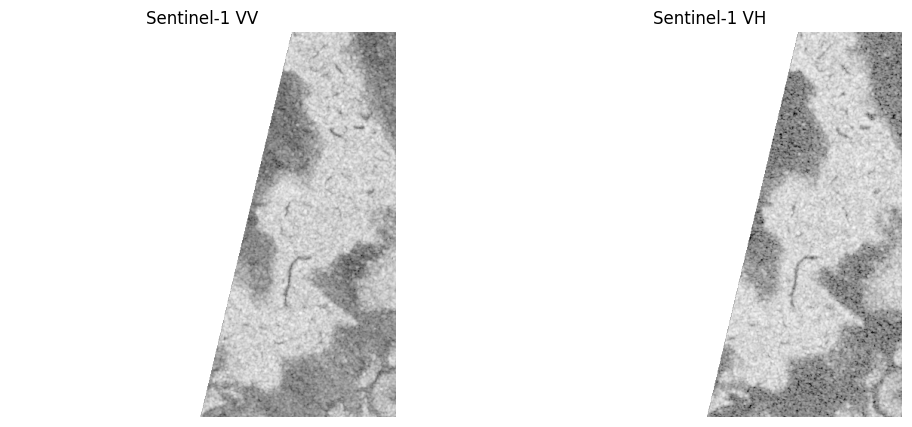

In [4]:
### vv and vh representation
import matplotlib.pyplot as plt

with rasterio.open(image_path) as src:
    vv = src.read(1)
    vh = src.read(2)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(vv, cmap="gray")
plt.title("Sentinel-1 VV")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(vh, cmap="gray")
plt.title("Sentinel-1 VH")
plt.axis("off")

plt.show()

In [5]:
print("VV mean:", np.nanmean(vv))
print("VH mean:", np.nanmean(vh))

print("VV range:", np.nanmin(vv), np.nanmax(vv))
print("VH range:", np.nanmin(vh), np.nanmax(vh))

VV mean: -13.010354
VH mean: -19.286884
VV range: -40.82144 -0.69059896
VH range: -48.24836 -6.9946613


In [6]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label shape:", label.shape)
print("Label data type:", label.dtype)
print("Unique label values:", np.unique(label))

Label shape: (512, 512)
Label data type: int16
Unique label values: [-1  0  1]


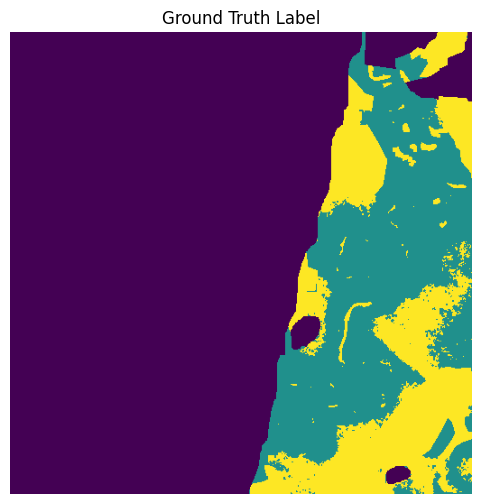

In [7]:
### Ground-Truth Label Inspection
plt.figure(figsize=(6, 6))

plt.imshow(label)
plt.title("Ground Truth Label")
plt.axis("off")

plt.show()

In [8]:
import os
import rasterio
import numpy as np
jrc_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\JRCWaterHand" # provides permanent-water info

jrc_name = "Bolivia_103757_JRCWaterHand.tif"
jrc_path = os.path.join(jrc_folder, jrc_name)

with rasterio.open(jrc_path) as src:
    jrc = src.read(1)

print("JRC shape:", jrc.shape)
print("JRC pixels with permanent water:", np.sum(jrc == 1))
print("JRC water percentage:", np.sum(jrc == 1) / jrc.size * 100)

JRC shape: (512, 512)
JRC pixels with permanent water: 0
JRC water percentage: 0.0


In [9]:
jrc_files = os.listdir(jrc_folder)

print("Total JRC files:", len(jrc_files))

for file in jrc_files[:10]:
    path = os.path.join(jrc_folder, file)
    with rasterio.open(path) as src:
        data = src.read(1)
        print(file, np.unique(data))

Total JRC files: 446
Bolivia_103757_JRCWaterHand.tif [0]
Bolivia_129334_JRCWaterHand.tif [0 1]
Bolivia_195474_JRCWaterHand.tif [0]
Bolivia_23014_JRCWaterHand.tif [0 1]
Bolivia_233925_JRCWaterHand.tif [0]
Bolivia_242570_JRCWaterHand.tif [0]
Bolivia_290290_JRCWaterHand.tif [0 1]
Bolivia_294583_JRCWaterHand.tif [0 1]
Bolivia_312675_JRCWaterHand.tif [0]
Bolivia_314919_JRCWaterHand.tif [0 1]


In [10]:
print("JRC unique values:", np.unique(jrc))
print("Number of pixels:", jrc.size)
print("Number of JRC water pixels:", np.sum(jrc == 1))

JRC unique values: [0]
Number of pixels: 262144
Number of JRC water pixels: 0


In [11]:
with rasterio.open(label_path) as src:
    label = src.read(1)

print("Label values:", np.unique(label))

print("Label water pixels:", np.sum(label == 1))
print("Permanent water pixels:", np.sum(jrc == 1))

overlap = np.sum((label == 1) & (jrc == 1))

print("Water + permanent water overlap:", overlap)

Label values: [-1  0  1]
Label water pixels: 35362
Permanent water pixels: 0
Water + permanent water overlap: 0


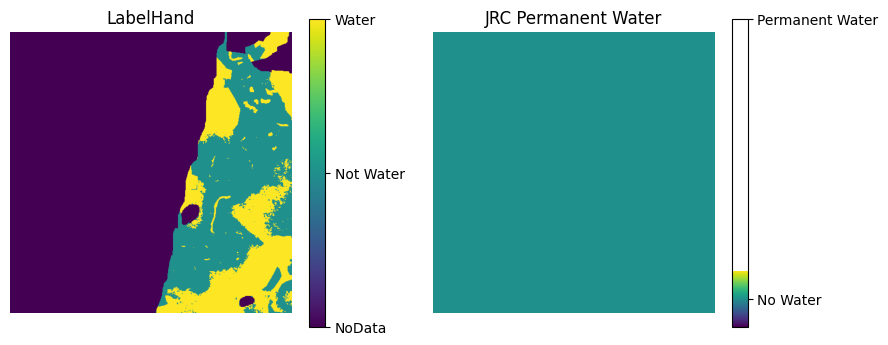

In [12]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(label)
plt.title("LabelHand")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([-1, 0, 1])
c.set_ticklabels(["NoData", "Not Water", "Water"])

plt.subplot(1, 2, 2)
plt.imshow(jrc)
plt.title("JRC Permanent Water")
plt.axis("off")
c = plt.colorbar()
c.set_ticks([0, 1])
c.set_ticklabels(["No Water", "Permanent Water"])

plt.show()

In [13]:
three_class = np.zeros_like(label, dtype=np.uint8)

# 0 = Land / Not Water
# 1 = Permanent Water
# 2 = Event / Non-permanent Water
# 255 = NoData

three_class[label == 1] = 2
three_class[(label == 1) & (jrc == 1)] = 1
three_class[label == -1] = 255

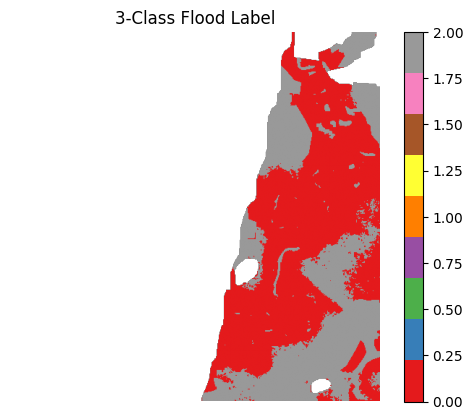

In [14]:
plt.imshow(np.ma.masked_equal(three_class, 255), cmap="Set1", vmin=0, vmax=2)
plt.title("3-Class Flood Label")
plt.colorbar()
plt.axis("off")
plt.show()

In [15]:
def make_three_class_label(label_path, jrc_path):

    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # 0 = Land / Not Water
    # 1 = Permanent Water
    # 2 = Event / Non-permanent Water
    # 255 = NoData

    three_class[label == 1] = 2
    three_class[(label == 1) & (jrc == 1)] = 1
    three_class[label == -1] = 255

    return three_class

In [16]:
class_counts = {
    0: 0,
    1: 0,
    2: 0,
    255: 0
}

processed = 0

for file in os.listdir(label_folder):

    if not file.endswith("_LabelHand.tif"):
        continue

    label_path = os.path.join(label_folder, file)

    # Find the matching JRC file
    jrc_filename = file.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(jrc_folder, jrc_filename)

    if not os.path.exists(jrc_path):
        continue

    three_class = make_three_class_label(
        label_path,
        jrc_path
    )

    for value in class_counts:
        class_counts[value] += np.sum(three_class == value)

    processed += 1

print("Images processed:", processed)

total_pixels = sum(class_counts.values())
valid_pixels = total_pixels - class_counts[255]

print("Total pixels:", total_pixels)
print("Valid pixels:", valid_pixels)
print("NoData pixels:", class_counts[255])

for value, name in [
    (0, "No Water"),
    (1, "Permanent Water"),
    (2, "Flooded Water")
]:
    count = class_counts[value]
    percentage = count / valid_pixels * 100

    print(
        f"Class {value} - {name}: "
        f"{count:,} pixels ({percentage:.2f}%)"
    )

Images processed: 446
Total pixels: 116916224
Valid pixels: 100983314
NoData pixels: 15932910
Class 0 - No Water: 90,277,709 pixels (89.40%)
Class 1 - Permanent Water: 3,062,228 pixels (3.03%)
Class 2 - Flooded Water: 7,643,377 pixels (7.57%)


In [17]:
# for 1 img
for value in [0, 1, 2, 255]:
    print(value, ":", np.sum(three_class == value))

0 : 260121
1 : 290
2 : 1607
255 : 126


In [18]:
total = np.sum(three_class != 255)

for value, name in [(0, "Land"), (1, "Permanent Water"), (2, "Flooded Land")]:
    count = np.sum(three_class == value)
    print(name, ":", count, "pixels,", round(count / total * 100, 2), "%")

Land : 260121 pixels, 99.28 %
Permanent Water : 290 pixels, 0.11 %
Flooded Land : 1607 pixels, 0.61 %


In [19]:
print("VV - valid pixels:", np.sum(np.isfinite(vv)))
print("VV - total pixels:", vv.size)

print("VH - valid pixels:", np.sum(np.isfinite(vh)))
print("VH - total pixels:", vh.size)

print("\nVV - NaN pixels:", np.sum(np.isnan(vv)))
print("VH - NaN pixels:", np.sum(np.isnan(vh)))

VV - valid pixels: 101623
VV - total pixels: 262144
VH - valid pixels: 101623
VH - total pixels: 262144

VV - NaN pixels: 160521
VH - NaN pixels: 160521


In [20]:
split_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\splits\flood_handlabeled"

In [21]:
train_df = pd.read_csv(
    os.path.join(split_folder, "flood_train_data.csv"),
    header=None,
    names=["s1", "label"]
)

valid_df = pd.read_csv(
    os.path.join(split_folder, "flood_valid_data.csv"),
    header=None,
    names=["s1", "label"]
)

test_df = pd.read_csv(
    os.path.join(split_folder, "flood_test_data.csv"),
    header=None,
    names=["s1", "label"]
)

In [22]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))


Train: 252
Validation: 89
Test: 90


In [23]:
print("\nColumns:")
print(train_df.columns.tolist())


Columns:
['s1', 'label']


In [24]:
vv_min = np.inf
vv_max = -np.inf
vh_min = np.inf
vh_max = -np.inf

for filename in train_df.iloc[:, 0]:
    if filename.endswith("_S1Hand.tif"):
        path = os.path.join(s1_folder, filename)

        with rasterio.open(path) as src:
            vv = src.read(1)
            vh = src.read(2)

        vv_valid = vv[np.isfinite(vv)]
        vh_valid = vh[np.isfinite(vh)]

        if len(vv_valid) > 0:
            vv_min = min(vv_min, vv_valid.min())
            vv_max = max(vv_max, vv_valid.max())

        if len(vh_valid) > 0:
            vh_min = min(vh_min, vh_valid.min())
            vh_max = max(vh_max, vh_valid.max())

print("Global VV range:", vv_min, "to", vv_max)
print("Global VH range:", vh_min, "to", vh_max)


Global VV range: -65.45004 to 29.926394
Global VH range: -79.161446 to 17.376385


In [25]:
# ============================================
# TRAINING SET VV/VH PERCENTILES
# ============================================

vv_values = []
vh_values = []

for filename in train_df["s1"]:

    path = os.path.join(s1_folder, filename)

    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

    vv_values.extend(vv[np.isfinite(vv)])
    vh_values.extend(vh[np.isfinite(vh)])

vv_values = np.array(vv_values)
vh_values = np.array(vh_values)

print("VV 2nd percentile :", np.percentile(vv_values, 2))
print("VV 98th percentile:", np.percentile(vv_values, 98))

print("VH 2nd percentile :", np.percentile(vh_values, 2))
print("VH 98th percentile:", np.percentile(vh_values, 98))

VV 2nd percentile : -21.938955
VV 98th percentile: -3.7259994
VH 2nd percentile : -30.85579
VH 98th percentile: -10.4768305


In [26]:
from scipy.ndimage import median_filter

def preprocess_s1(path):

    with rasterio.open(path) as src:
        vv = src.read(1).astype(np.float32)
        vh = src.read(2).astype(np.float32)

    nodata_mask = np.isnan(vv) | np.isnan(vh)

    # Original normalization
    vv_norm = (vv - vv_min) / (vv_max - vv_min)
    vh_norm = (vh - vh_min) / (vh_max - vh_min)

    vv_temp = np.nan_to_num(vv_norm, nan=0.0)
    vh_temp = np.nan_to_num(vh_norm, nan=0.0)

    vv_filtered = median_filter(vv_temp, size=3)
    vh_filtered = median_filter(vh_temp, size=3)

    vv_filtered[nodata_mask] = 0.0
    vh_filtered[nodata_mask] = 0.0

    return np.stack([vv_filtered, vh_filtered], axis=0)

In [27]:
sample_filename = train_df.iloc[0]["s1"]
sample_path = os.path.join(s1_folder, sample_filename)

sample_input = preprocess_s1(sample_path)

print("Shape:", sample_input.shape)
print("VV range:", sample_input[0].min(), "to", sample_input[0].max())
print("VH range:", sample_input[1].min(), "to", sample_input[1].max())
print("Finite:", np.isfinite(sample_input).all())

Shape: (2, 512, 512)
VV range: 0.3978222 to 0.7441679
VH range: 0.32924446 to 0.7858727
Finite: True


In [28]:
sample_filename = train_df.iloc[0, 0]
sample_path = os.path.join(s1_folder, sample_filename)

sample_input = preprocess_s1(sample_path)

print("File:", sample_filename)
print("Shape:", sample_input.shape)
print("VV range:", np.nanmin(sample_input[0]), "to", np.nanmax(sample_input[0]))
print("VH range:", np.nanmin(sample_input[1]), "to", np.nanmax(sample_input[1]))

File: Ghana_103272_S1Hand.tif
Shape: (2, 512, 512)
VV range: 0.3978222 to 0.7441679
VH range: 0.32924446 to 0.7858727


In [29]:
def make_three_class_label(label_path, jrc_path):
    with rasterio.open(label_path) as src:
        label = src.read(1)

    with rasterio.open(jrc_path) as src:
        jrc = src.read(1)

    three_class = np.zeros_like(label, dtype=np.uint8)

    # Water → initially Flooded Land
    three_class[label == 1] = 2

    # Water + JRC permanent water → Permanent Water
    three_class[(label == 1) & (jrc == 1)] = 1

    # Label NoData
    three_class[label == -1] = 255

    return three_class

In [30]:
def class_distribution(df):

    counts = {
        0: 0,
        1: 0,
        2: 0,
        255: 0
    }

    for label_filename in df.iloc[:, 1]:

        if not label_filename.endswith("_LabelHand.tif"):
            continue

        label_path = os.path.join(
            label_folder,
            label_filename
        )

        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )

        jrc_path = os.path.join(
            jrc_folder,
            jrc_filename
        )

        if not os.path.exists(jrc_path):
            continue

        three_class = make_three_class_label(
            label_path,
            jrc_path
        )

        for value in counts:
            counts[value] += np.sum(
                three_class == value
            )

    return counts

In [31]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(51856372), 1: np.int64(1521824), 2: np.int64(3925211), 255: np.int64(8756881)}
Validation: {0: np.int64(18057120), 1: np.int64(611055), 2: np.int64(1626550), 255: np.int64(3036091)}
Test: {0: np.int64(17951266), 1: np.int64(899398), 2: np.int64(1666703), 255: np.int64(3075593)}


In [32]:
print("Train:", len(train_df))
print("Validation:", len(valid_df))
print("Test:", len(test_df))

print(train_df.head())

Train: 252
Validation: 89
Test: 90
                        s1                       label
0  Ghana_103272_S1Hand.tif  Ghana_103272_LabelHand.tif
1   Ghana_24858_S1Hand.tif   Ghana_24858_LabelHand.tif
2  Ghana_147015_S1Hand.tif  Ghana_147015_LabelHand.tif
3  Ghana_953791_S1Hand.tif  Ghana_953791_LabelHand.tif
4  Ghana_154838_S1Hand.tif  Ghana_154838_LabelHand.tif


In [33]:
vv_min, vv_max = np.inf, -np.inf
vh_min, vh_max = np.inf, -np.inf

for filename in train_df["s1"]:
    path = os.path.join(s1_folder, filename)

    with rasterio.open(path) as src:
        vv = src.read(1)
        vh = src.read(2)

    vv_valid = vv[~np.isnan(vv)]
    vh_valid = vh[~np.isnan(vh)]

    vv_min = min(vv_min, vv_valid.min())
    vv_max = max(vv_max, vv_valid.max())

    vh_min = min(vh_min, vh_valid.min())
    vh_max = max(vh_max, vh_valid.max())

print("VV:", vv_min, "to", vv_max)
print("VH:", vh_min, "to", vh_max)

VV: -65.45004 to 29.926394
VH: -79.161446 to 17.376385


In [34]:
def class_distribution(df):
    counts = {0: 0, 1: 0, 2: 0, 255: 0}

    for label_filename in df["label"]:
        label_path = os.path.join(label_folder, label_filename)

        # Corresponding JRC filename
        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )
        jrc_path = os.path.join(jrc_folder, jrc_filename)

        with rasterio.open(label_path) as src:
            label = src.read(1)

        with rasterio.open(jrc_path) as src:
            jrc = src.read(1)

        three_class = np.zeros_like(label, dtype=np.uint8)

        # Flooded land
        three_class[label == 1] = 2

        # Permanent water
        three_class[(label == 1) & (jrc == 1)] = 1

        # NoData
        three_class[label == -1] = 255

        for cls in counts:
            counts[cls] += np.sum(three_class == cls)

    return counts

In [35]:
train_counts = class_distribution(train_df)
valid_counts = class_distribution(valid_df)
test_counts = class_distribution(test_df)

print("Train:", train_counts)
print("Validation:", valid_counts)
print("Test:", test_counts)

Train: {0: np.int64(51856372), 1: np.int64(1521824), 2: np.int64(3925211), 255: np.int64(8756881)}
Validation: {0: np.int64(18057120), 1: np.int64(611055), 2: np.int64(1626550), 255: np.int64(3036091)}
Test: {0: np.int64(17951266), 1: np.int64(899398), 2: np.int64(1666703), 255: np.int64(3075593)}


In [36]:
def class_percentages(counts):

    valid_total = counts[0] + counts[1] + counts[2]

    return {
        "Land": counts[0] / valid_total * 100,
        "Permanent Water": counts[1] / valid_total * 100,
        "Flooded Land": counts[2] / valid_total * 100
    }

print("Train:", class_percentages(train_counts))
print("Validation:", class_percentages(valid_counts))
print("Test:", class_percentages(test_counts))

Train: {'Land': np.float64(90.49439590912979), 'Permanent Water': np.float64(2.655730400113906), 'Flooded Land': np.float64(6.849873690756294)}
Validation: {'Land': np.float64(88.97445025739447), 'Permanent Water': np.float64(3.0109055431891787), 'Flooded Land': np.float64(8.01464419941635)}
Test: {'Land': np.float64(87.49302968553421), 'Permanent Water': np.float64(4.383593664820637), 'Flooded Land': np.float64(8.123376649645152)}


In [37]:
import numpy as np
import os

tile_stats = []

for idx, row in train_df.iterrows():

    label_filename = row["label"]

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Create 3-class label
    three_class = make_three_class_label(
        label_path,
        jrc_path
    )

    # Ignore NoData
    valid_pixels = three_class != 255

    total = np.sum(valid_pixels)

    land = np.sum(three_class == 0)
    permanent_water = np.sum(three_class == 1)
    flooded_land = np.sum(three_class == 2)

    tile_stats.append({
        "filename": label_filename,
        "land_pct": land / total * 100,
        "permanent_water_pct": permanent_water / total * 100,
        "non_permanent_water_pct": flooded_land / total * 100
    })

print("Number of training tiles:", len(tile_stats))

print("\nFirst 10 tiles:")
for item in tile_stats[:10]:
    print(item)

C:\Users\GNANA SRIHASA\AppData\Local\Temp\ipykernel_27864\2160992302.py:42: RuntimeWarning: invalid value encountered in scalar divide
  "land_pct": land / total * 100,
C:\Users\GNANA SRIHASA\AppData\Local\Temp\ipykernel_27864\2160992302.py:43: RuntimeWarning: invalid value encountered in scalar divide
  "permanent_water_pct": permanent_water / total * 100,
C:\Users\GNANA SRIHASA\AppData\Local\Temp\ipykernel_27864\2160992302.py:44: RuntimeWarning: invalid value encountered in scalar divide
  "non_permanent_water_pct": flooded_land / total * 100


Number of training tiles: 252

First 10 tiles:
{'filename': 'Ghana_103272_LabelHand.tif', 'land_pct': np.float64(99.3990797202905), 'permanent_water_pct': np.float64(0.1446374229082536), 'non_permanent_water_pct': np.float64(0.4562828568012373)}
{'filename': 'Ghana_24858_LabelHand.tif', 'land_pct': np.float64(99.81536865234375), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(0.18463134765625)}
{'filename': 'Ghana_147015_LabelHand.tif', 'land_pct': np.float64(98.65341186523438), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(1.346588134765625)}
{'filename': 'Ghana_953791_LabelHand.tif', 'land_pct': np.float64(98.94256591796875), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(1.05743408203125)}
{'filename': 'Ghana_154838_LabelHand.tif', 'land_pct': np.float64(100.0), 'permanent_water_pct': np.float64(0.0), 'non_permanent_water_pct': np.float64(0.0)}
{'filename': 'Ghana_134751_LabelHand.tif', 'lan

In [38]:
# ============================================
# STEP 2: SUMMARIZE TRAINING TILE TYPES
# ============================================

land_only = 0
non_permanent_water_tiles = 0
water_tiles = 0
both_minority = 0
empty_tiles = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    # Completely invalid / empty tile
    if np.isnan(water) or np.isnan(flood):
        empty_tiles += 1

    # Contains both minority classes
    elif water > 0 and flood > 0:
        both_minority += 1

    # Contains permanent water
    elif water > 0:
        water_tiles += 1

    # Contains flooded land
    elif flood > 0:
        non_permanent_water_tiles += 1

    # Only land
    else:
        land_only += 1


print("================================")
print("TRAINING TILE SUMMARY")
print("================================")

print("Total tiles:", len(tile_stats))
print("Land-only tiles:", land_only)
print("Flood-containing tiles:", non_permanent_water_tiles)
print("Permanent-water tiles:", water_tiles)
print("Both minority classes:", both_minority)
print("Empty/invalid tiles:", empty_tiles)

TRAINING TILE SUMMARY
Total tiles: 252
Land-only tiles: 32
Flood-containing tiles: 98
Permanent-water tiles: 0
Both minority classes: 121
Empty/invalid tiles: 1


In [39]:
# ============================================
# STEP 3: MINORITY CLASS DISTRIBUTION
# ============================================

water_percentages = []
flood_percentages = []

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if not np.isnan(water):
        water_percentages.append(water)

    if not np.isnan(flood):
        flood_percentages.append(flood)


print("================================")
print("MINORITY CLASS DISTRIBUTION")
print("================================")

print("\nPermanent Water:")
print("Average :", np.mean(water_percentages), "%")
print("Median  :", np.median(water_percentages), "%")
print("Maximum :", np.max(water_percentages), "%")

print("\nFlooded Land:")
print("Average :", np.mean(flood_percentages), "%")
print("Median  :", np.median(flood_percentages), "%")
print("Maximum :", np.max(flood_percentages), "%")

MINORITY CLASS DISTRIBUTION

Permanent Water:
Average : 2.631178206448873 %
Median  : 0.0 %
Maximum : 97.09002400750961 %

Flooded Land:
Average : 6.747253376489373 %
Median  : 1.848602294921875 %
Maximum : 84.20372009277344 %


In [40]:
# ============================================
# STEP 4: COUNT MINORITY-RICH TILES
# ============================================

water_1 = 0
water_5 = 0
flood_1 = 0
flood_5 = 0
both_5 = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if water >= 1:
        water_1 += 1

    if water >= 5:
        water_5 += 1

    if flood >= 1:
        flood_1 += 1

    if flood >= 5:
        flood_5 += 1

    if water >= 5 and flood >= 5:
        both_5 += 1


print("================================")
print("MINORITY-RICH TILE COUNTS")
print("================================")

print("Permanent Water >= 1% :", water_1)
print("Permanent Water >= 5% :", water_5)

print("Flooded Land >= 1%    :", flood_1)
print("Flooded Land >= 5%    :", flood_5)

print("Both >= 5%            :", both_5)

MINORITY-RICH TILE COUNTS
Permanent Water >= 1% : 45
Permanent Water >= 5% : 26
Flooded Land >= 1%    : 155
Flooded Land >= 5%    : 80
Both >= 5%            : 15


In [41]:
# ============================================
# STEP 5: ESTIMATE AUGMENTED DATASET SIZE
# ============================================

total_samples = 0

for item in tile_stats:

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    if water >= 5:
        multiplier = 5       # original + 4 augmentations

    elif flood >= 5:
        multiplier = 3       # original + 2 augmentations

    else:
        multiplier = 1       # original only

    total_samples += multiplier

print("================================")
print("AUGMENTATION SIZE ESTIMATE")
print("================================")
print("Original training tiles :", len(tile_stats))
print("Estimated final samples :", total_samples)
print("Additional samples      :", total_samples - len(tile_stats))

AUGMENTATION SIZE ESTIMATE
Original training tiles : 252
Estimated final samples : 486
Additional samples      : 234


In [42]:
from pathlib import Path
import os
import numpy as np

BASE_DIR = Path.home() / "Desktop" / "Sen1Floods11" / "v1.1"

aug_image_dir = os.path.join(BASE_DIR, "Augmented_S1")
aug_label_folder = os.path.join(BASE_DIR, "Augmented_Labels")

os.makedirs(aug_image_dir, exist_ok=True)
os.makedirs(aug_label_folder, exist_ok=True)

print("Augmented image folder:", aug_image_dir)
print("Augmented label folder:", aug_label_folder)

Augmented image folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Augmented_S1
Augmented label folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Augmented_Labels


In [43]:
# ============================================
# STEP 6: ACTUAL CLASS-AWARE AUGMENTATION
# ============================================

def apply_augmentation(image, label, aug_name):

    if aug_name == "horizontal_flip":
        image_aug = np.flip(image, axis=2)
        label_aug = np.flip(label, axis=1)

    elif aug_name == "vertical_flip":
        image_aug = np.flip(image, axis=1)
        label_aug = np.flip(label, axis=0)

    elif aug_name == "rotate_90":
        image_aug = np.rot90(image, k=1, axes=(1, 2))
        label_aug = np.rot90(label, k=1)

    elif aug_name == "rotate_180":
        image_aug = np.rot90(image, k=2, axes=(1, 2))
        label_aug = np.rot90(label, k=2)

    else:
        raise ValueError("Unknown augmentation")

    return image_aug.copy(), label_aug.copy()


created = 0

for item in tile_stats:

    label_filename = item["filename"]

    image_filename = label_filename.replace(
        "_LabelHand.tif",
        "_S1Hand.tif"
    )

    image_path = os.path.join(
        s1_folder,
        image_filename
    )

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    # JRC water file
    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    # Preprocess image
    image = preprocess_s1(image_path)

    # Create 3-class label
    label = make_three_class_label(
        label_path,
        jrc_path
    )

    water = item["permanent_water_pct"]
    flood = item["non_permanent_water_pct"]

    # Class-aware augmentation
    if water >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip",
            "rotate_90",
            "rotate_180"
        ]

    elif flood >= 5:
        selected_augs = [
            "horizontal_flip",
            "vertical_flip"
        ]

    else:
        selected_augs = []

    base_name = label_filename.replace(
        "_LabelHand.tif",
        ""
    )

    for aug_name in selected_augs:

        aug_image, aug_label = apply_augmentation(
            image,
            label,
            aug_name
        )

        image_out = os.path.join(
            aug_image_dir,
            f"{base_name}_{aug_name}.npy"
        )

        label_out = os.path.join(
            aug_label_folder,
            f"{base_name}_{aug_name}.npy"
        )

        np.save(image_out, aug_image)
        np.save(label_out, aug_label)

        created += 1


print("================================")
print("DATA AUGMENTATION COMPLETED")
print("================================")
print("Original training tiles :", len(tile_stats))
print("New augmented samples   :", created)
print("Final training samples  :", len(tile_stats) + created)

DATA AUGMENTATION COMPLETED
Original training tiles : 252
New augmented samples   : 234
Final training samples  : 486


In [44]:
aug_files = [
    f for f in os.listdir(aug_image_dir)
    if f.endswith(".npy")
]

test_aug = np.load(
    os.path.join(aug_image_dir, aug_files[0])
)

print("Shape:", test_aug.shape)
print("VV range:", test_aug[0].min(), "to", test_aug[0].max())
print("VH range:", test_aug[1].min(), "to", test_aug[1].max())
print("Finite:", np.isfinite(test_aug).all())

Shape: (2, 512, 512)
VV range: 0.35602224 to 0.6838547
VH range: 0.3304895 to 0.72512054
Finite: True


In [45]:
# ============================================
# CLASS DISTRIBUTION AFTER AUGMENTATION
# ============================================

after_counts = {
    0: 0,
    1: 0,
    2: 0
}

# 1. Count original training labels
for label_filename in train_df["label"]:

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    jrc_filename = label_filename.replace(
        "_LabelHand.tif",
        "_JRCWaterHand.tif"
    )

    jrc_path = os.path.join(
        jrc_folder,
        jrc_filename
    )

    label = make_three_class_label(
        label_path,
        jrc_path
    )

    for cls in range(3):
        after_counts[cls] += np.sum(label == cls)


# 2. Count augmented labels
for filename in os.listdir(aug_label_folder):

    if filename.endswith(".npy"):

        label = np.load(
            os.path.join(aug_label_folder, filename)
        )

        for cls in range(3):
            after_counts[cls] += np.sum(label == cls)


# Calculate percentages
total_valid = sum(after_counts.values())

print("================================")
print("CLASS DISTRIBUTION AFTER AUGMENTATION")
print("================================")

for cls, name in [
    (0, "No Water"),
    (1, "Permanent Water"),
    (2, "Non-permanent Water")
]:

    percentage = after_counts[cls] / total_valid * 100

    print(
        f"Class {cls} - {name}: "
        f"{after_counts[cls]:,} pixels "
        f"({percentage:.2f}%)"
    )

CLASS DISTRIBUTION AFTER AUGMENTATION
Class 0 - No Water: 91,713,110 pixels (82.38%)
Class 1 - Permanent Water: 7,219,772 pixels (6.49%)
Class 2 - Non-permanent Water: 12,392,993 pixels (11.13%)


In [46]:
import os

print("Augmented images:", len(os.listdir(aug_image_dir)))
print("Augmented labels:", len(os.listdir(aug_label_folder)))

print("\nSample augmented images:")
print(os.listdir(aug_image_dir)[:5])

print("\nSample augmented labels:")
print(os.listdir(aug_label_folder)[:5])

Augmented images: 234
Augmented labels: 234

Sample augmented images:
['Ghana_141910_horizontal_flip.npy', 'Ghana_141910_vertical_flip.npy', 'Ghana_247288_horizontal_flip.npy', 'Ghana_247288_vertical_flip.npy', 'Ghana_362274_horizontal_flip.npy']

Sample augmented labels:
['Ghana_141910_horizontal_flip.npy', 'Ghana_141910_vertical_flip.npy', 'Ghana_247288_horizontal_flip.npy', 'Ghana_247288_vertical_flip.npy', 'Ghana_362274_horizontal_flip.npy']


In [47]:
print("Original S1 folder:", s1_folder)
print("Original label folder:", label_folder)
print("Augmented S1 folder:", aug_image_dir)
print("Augmented label folder:", aug_label_folder)

Original S1 folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\S1Hand
Original label folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand
Augmented S1 folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Augmented_S1
Augmented label folder: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Augmented_Labels


In [53]:
pip install torch torchvision torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.9/679.9 kB 8.4 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [164]:
import torch
from torch.utils.data import Dataset
import numpy as np
import os

class AugmentedFloodDataset(Dataset):

    def __init__(
        self,
        train_df,
        s1_folder,
        label_folder,
        jrc_folder,
        augmented_image_dir=None,
        augmented_label_folder=None,
        include_augmented=True
    ):

        self.samples = []

        # ==========================================
        # 1. ORIGINAL TRAINING SAMPLES
        # ==========================================

        for i in range(len(train_df)):

            s1_filename = train_df.iloc[i]["s1"]
            label_filename = train_df.iloc[i]["label"]

            s1_path = os.path.join(
                s1_folder,
                s1_filename
            )

            label_path = os.path.join(
                label_folder,
                label_filename
            )

            jrc_filename = label_filename.replace(
                "_LabelHand.tif",
                "_JRCWaterHand.tif"
            )

            jrc_path = os.path.join(
                jrc_folder,
                jrc_filename
            )

            self.samples.append(
                (
                    "original",
                    s1_path,
                    label_path,
                    jrc_path
                )
            )

        # ==========================================
        # 2. AUGMENTED TRAINING SAMPLES
        # ==========================================

        if include_augmented and augmented_image_dir and augmented_label_folder:
            for filename in os.listdir(augmented_image_dir):
                if filename.endswith(".npy"):
                    image_path = os.path.join(augmented_image_dir, filename)
                    label_path = os.path.join(augmented_label_folder, filename)
        
                    if os.path.exists(label_path):
                        self.samples.append(
                            ("augmented", image_path, label_path, None)
                        )

    # ==========================================
    # NUMBER OF SAMPLES
    # ==========================================

    def __len__(self):

        return len(self.samples)

    # ==========================================
    # LOAD ONE SAMPLE
    # ==========================================

    def __getitem__(self, idx):

        sample_type, image_path, label_path, jrc_path = self.samples[idx]

        # ------------------------------------------
        # ORIGINAL TIFF
        # ------------------------------------------

        if sample_type == "original":

            image = preprocess_s1(image_path)

            label = make_three_class_label(
                label_path,
                jrc_path
            )

        # ------------------------------------------
        # AUGMENTED NPY
        # ------------------------------------------

        else:

            image = np.load(image_path)
            label = np.load(label_path)

        # Convert to PyTorch tensors

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label


# ==============================================
# CREATE DATASET
# ==============================================

def is_valid_label(label):
    return np.any(label != 255)

valid_indices = []

for i in range(len(train_df)):

    label_filename = train_df.iloc[i]["label"]

    label_path = os.path.join(
        label_folder,
        label_filename
    )

    with rasterio.open(label_path) as src:
        label = src.read(1)

    if np.any(label != 255):
        valid_indices.append(i)

valid_train_df = train_df.iloc[valid_indices].reset_index(drop=True)

print("Original training samples:", len(train_df))
print("Valid training samples:", len(valid_train_df))
print("Removed invalid samples:", len(train_df) - len(valid_train_df))

train_dataset = AugmentedFloodDataset(
    valid_train_df,
    s1_folder,
    label_folder,
    jrc_folder,
    aug_image_dir,
    aug_label_folder
)

print("Original training samples:", len(train_df))
print("Augmented training samples:", len(os.listdir(aug_image_dir)))
print("Total training samples:", len(train_dataset))

Original training samples: 252
Valid training samples: 252
Removed invalid samples: 0
Original training samples: 252
Augmented training samples: 234
Total training samples: 486


In [58]:
# Test original sample
image1, label1 = train_dataset[0]

print("ORIGINAL SAMPLE")
print("Image shape:", image1.shape)
print("Label shape:", label1.shape)
print("Image dtype:", image1.dtype)
print("Label dtype:", label1.dtype)
print("Image finite:", torch.isfinite(image1).all().item())
print("Label min:", label1.min().item())
print("Label max:", label1.max().item())

ORIGINAL SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 255


In [59]:
print("Number of samples:", len(train_dataset.samples))

print("\nFirst sample:")
print(train_dataset.samples[0])

print("\nFirst augmented sample:")
print(train_dataset.samples[-1])

Number of samples: 486

First sample:
('original', 'C:\\Users\\GNANA SRIHASA\\Desktop\\Sen1Floods11\\v1.1\\data\\flood_events\\HandLabeled\\S1Hand\\Ghana_103272_S1Hand.tif', 'C:\\Users\\GNANA SRIHASA\\Desktop\\Sen1Floods11\\v1.1\\data\\flood_events\\HandLabeled\\LabelHand\\Ghana_103272_LabelHand.tif', 'C:\\Users\\GNANA SRIHASA\\Desktop\\Sen1Floods11\\v1.1\\data\\flood_events\\HandLabeled\\JRCWaterHand\\Ghana_103272_JRCWaterHand.tif')

First augmented sample:
('augmented', 'C:\\Users\\GNANA SRIHASA\\Desktop\\Sen1Floods11\\v1.1\\Augmented_S1\\USA_955053_vertical_flip.npy', 'C:\\Users\\GNANA SRIHASA\\Desktop\\Sen1Floods11\\v1.1\\Augmented_Labels\\USA_955053_vertical_flip.npy', None)


In [60]:
# Find an augmented sample

aug_indices = [
    i for i, sample in enumerate(train_dataset.samples)
    if sample[0] == "augmented"
]

print("Number of augmented samples:", len(aug_indices))

# Load the first augmented sample
idx = aug_indices[0]

image2, label2 = train_dataset[idx]

print("\nAUGMENTED SAMPLE")
print("Image shape:", image2.shape)
print("Label shape:", label2.shape)
print("Image dtype:", image2.dtype)
print("Label dtype:", label2.dtype)
print("Image finite:", torch.isfinite(image2).all().item())
print("Label min:", label2.min().item())
print("Label max:", label2.max().item())

Number of augmented samples: 234

AUGMENTED SAMPLE
Image shape: torch.Size([2, 512, 512])
Label shape: torch.Size([512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Image finite: True
Label min: 0
Label max: 2


In [61]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler
import numpy as np

# ============================================
# CREATE SAMPLE WEIGHTS FOR CLASS IMBALANCE
# ============================================

sample_weights = []

for i in range(len(train_dataset)):

    # Load image and label through our dataset
    _, label = train_dataset[i]

    # Ignore NoData (255)
    valid = label != 255

    # Count minority-class pixels
    minority_pixels = ((label == 1) | (label == 2)) & valid

    if valid.sum() == 0:
        weight = 1.0
    else:
        minority_ratio = minority_pixels.sum().item() / valid.sum().item()

        # Higher weight for tiles containing more minority pixels
        weight = 1.0 + 4.0 * minority_ratio

    sample_weights.append(weight)

sample_weights = torch.tensor(sample_weights, dtype=torch.double)

# ============================================
# WEIGHTED SAMPLER
# ============================================

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# ============================================
# DATALOADER
# ============================================

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    sampler=sampler,
    num_workers=0
)

print("================================")
print("TRAINING DATALOADER READY")
print("================================")
print("Total samples:", len(train_dataset))
print("Batch size:", 4)
print("Number of batches:", len(train_loader))
print("Minimum sample weight:", sample_weights.min().item())
print("Maximum sample weight:", sample_weights.max().item())

TRAINING DATALOADER READY
Total samples: 486
Batch size: 4
Number of batches: 122
Minimum sample weight: 1.0
Maximum sample weight: 4.896792629943761


In [62]:
# ============================================
# TEST ONE TRAINING BATCH
# ============================================

images, labels = next(iter(train_loader))

print("BATCH TEST")
print("====================")
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Images dtype:", images.dtype)
print("Labels dtype:", labels.dtype)
print("Images finite:", torch.isfinite(images).all().item())
print("Labels min:", labels.min().item())
print("Labels max:", labels.max().item())

BATCH TEST
Images shape: torch.Size([4, 2, 512, 512])
Labels shape: torch.Size([4, 512, 512])
Images dtype: torch.float32
Labels dtype: torch.int64
Images finite: True
Labels min: 0
Labels max: 255


In [63]:
# ============================================
# ORIGINAL CLASS WEIGHTS
# ============================================

class_counts = np.zeros(3, dtype=np.int64)

for sample in train_dataset.samples:

    sample_type = sample[0]
    label_path = sample[2]

    if sample_type == "original":
        label = make_three_class_label(
            label_path,
            sample[3]
        )
    else:
        label = np.load(label_path)

    for cls in range(3):
        class_counts[cls] += np.sum(label == cls)

print("CLASS PIXEL COUNTS")
print("===================")
print("Land (0):", class_counts[0])
print("Permanent Water (1):", class_counts[1])
print("Event Water (2):", class_counts[2])

# Original inverse-frequency weights
class_weights = 1 / class_counts

# Normalize average weight to 1
class_weights = class_weights / class_weights.mean()

print("\nCLASS WEIGHTS")
print("=============")
print("Land:", class_weights[0])
print("Permanent Water:", class_weights[1])
print("Event Water:", class_weights[2])

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
)

print("\nPyTorch weights:", class_weights)

CLASS PIXEL COUNTS
Land (0): 91713110
Permanent Water (1): 7219772
Event Water (2): 12392993

CLASS WEIGHTS
Land: 0.14215686234881575
Permanent Water: 1.8058254407274632
Event Water: 1.052017696923721

PyTorch weights: tensor([0.1422, 1.8058, 1.0520])


In [64]:
class_weights = torch.tensor(
    [0.40461636, 5.13986106, 2.99432308],
    dtype=torch.float32
)

print("Class weights:", class_weights)

Class weights: tensor([0.4046, 5.1399, 2.9943])


In [65]:
import torch
import torch.nn as nn

# ============================================
# WEIGHTED CROSS ENTROPY LOSS
# ============================================

criterion_ce = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

print("Weighted Cross Entropy Loss ready")
print("Class weights:", class_weights)
print("Ignore index: 255")

Weighted Cross Entropy Loss ready
Class weights: tensor([0.4046, 5.1399, 2.9943])
Ignore index: 255


In [66]:
def dice_loss(pred, target, num_classes=3, ignore_index=255):
    pred = torch.softmax(pred, dim=1)

    valid = target != ignore_index

    total_loss = 0.0
    valid_classes = 0

    for cls in range(num_classes):

        pred_cls = pred[:, cls, :, :][valid]
        target_cls = (target == cls)[valid].float()

        intersection = (pred_cls * target_cls).sum()
        denominator = pred_cls.sum() + target_cls.sum()

        dice = (2.0 * intersection + 1e-6) / (denominator + 1e-6)

        total_loss += (1.0 - dice)
        valid_classes += 1

    return total_loss / valid_classes

In [67]:
# ============================================
# COMBINED LOSS
# ============================================

def combined_loss(pred, target):

    ce_loss = criterion_ce(pred, target)

    d_loss = dice_loss(pred, target)

    total_loss = ce_loss + d_loss

    return total_loss


print("Combined Loss function ready")

Combined Loss function ready


In [68]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class UNet(nn.Module):

    def __init__(self, in_channels=2, num_classes=3):
        super().__init__()

        # Encoder
        self.enc1 = self.double_conv(in_channels, 32)
        self.enc2 = self.double_conv(32, 64)
        self.enc3 = self.double_conv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = self.double_conv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = self.double_conv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = self.double_conv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = self.double_conv(64, 32)

        # Output
        self.final = nn.Conv2d(32, num_classes, 1)

    def double_conv(self, in_channels, out_channels):
        return nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoder + skip connections
        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return self.final(d1)

In [69]:
# ============================================
# TEST MODEL
# ============================================
model = UNet(in_channels=2, num_classes=3)
images, labels = next(iter(train_loader))

outputs = model(images)

print("MODEL TEST")
print("====================")
print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Labels shape:", labels.shape)

MODEL TEST
Input shape : torch.Size([4, 2, 512, 512])
Output shape: torch.Size([4, 3, 512, 512])
Labels shape: torch.Size([4, 512, 512])


In [70]:
# ============================================
# OPTIMIZER + TRAINING SETUP
# ============================================

import torch.optim as optim

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
class_weights = class_weights.to(device)

print("DEVICE:", device)
print("OPTIMIZER: Adam")
print("LEARNING RATE: 0.001")
print("TRAINING SETUP READY")

DEVICE: cpu
OPTIMIZER: Adam
LEARNING RATE: 0.001
TRAINING SETUP READY


In [72]:
# ============================================
# MODEL TRAINING
# ============================================

num_epochs = 10

for epoch in range(num_epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = combined_loss(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Training Loss: {avg_loss:.4f}"
    )

print("TRAINING COMPLETED")

Epoch [1/10] Training Loss: 1.2632
Epoch [2/10] Training Loss: 1.0995
Epoch [3/10] Training Loss: 1.1105
Epoch [4/10] Training Loss: 1.0195
Epoch [5/10] Training Loss: 1.0343
Epoch [6/10] Training Loss: 1.0158
Epoch [7/10] Training Loss: 1.0162
Epoch [8/10] Training Loss: 0.9496
Epoch [9/10] Training Loss: 0.9531
Epoch [10/10] Training Loss: 0.9409
TRAINING COMPLETED


In [73]:
# ==============================
# VALIDATION DATALOADER
# ==============================

from torch.utils.data import Dataset, DataLoader

class ValidationFloodDataset(Dataset):

    def __init__(self, dataframe):
        self.samples = dataframe

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        s1_filename = self.samples.iloc[idx]["s1"]
        label_filename = self.samples.iloc[idx]["label"]

        s1_path = os.path.join(s1_folder, s1_filename)
        label_path = os.path.join(label_folder, label_filename)

        jrc_filename = label_filename.replace(
            "_LabelHand.tif",
            "_JRCWaterHand.tif"
        )

        jrc_path = os.path.join(jrc_folder, jrc_filename)

        # Preprocess ONE validation image
        image = preprocess_s1(s1_path)

        # Create 3-class label
        label = make_three_class_label(
            label_path,
            jrc_path
        )

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            label,
            dtype=torch.long
        )

        return image, label


valid_dataset = ValidationFloodDataset(valid_df)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("VALIDATION DATALOADER READY")
print("Validation samples:", len(valid_dataset))
print("Validation batches:", len(valid_loader))

VALIDATION DATALOADER READY
Validation samples: 89
Validation batches: 23


In [74]:
# ==============================
# VALIDATION
# ==============================

model.eval()

validation_loss = 0.0

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = combined_loss(outputs, labels)

        validation_loss += loss.item()

avg_validation_loss = validation_loss / len(valid_loader)

print("VALIDATION COMPLETED")
print("Validation Loss:", avg_validation_loss)

VALIDATION COMPLETED
Validation Loss: 1.15749863308409


In [75]:
# ==============================
# TEST DATALOADER
# ==============================

test_dataset = ValidationFloodDataset(test_df)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

print("TEST DATALOADER READY")
print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

TEST DATALOADER READY
Test samples: 90
Test batches: 23


In [76]:
# ==============================
# FINAL TEST EVALUATION
# ==============================

model.eval()

test_loss = 0.0
total_correct = 0
total_pixels = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        # Loss
        loss = combined_loss(outputs, labels)
        test_loss += loss.item()

        # Predictions
        predictions = torch.argmax(outputs, dim=1)

        # Ignore NoData pixels
        valid_pixels = labels != 255

        total_correct += (
            (predictions == labels) & valid_pixels
        ).sum().item()

        total_pixels += valid_pixels.sum().item()


avg_test_loss = test_loss / len(test_loader)
pixel_accuracy = total_correct / total_pixels

print("================================")
print("FINAL TEST RESULTS")
print("================================")
print("Test Loss:", avg_test_loss)
print("Pixel Accuracy:", pixel_accuracy)
print("Pixel Accuracy (%):", pixel_accuracy * 100)

FINAL TEST RESULTS
Test Loss: 1.2302082867726036
Pixel Accuracy: 0.8634591368375873
Pixel Accuracy (%): 86.34591368375874


In [77]:
# ==========================================
# DICE + IoU FOR TEST SET
# ==========================================

model.eval()

class_intersection = torch.zeros(3)
class_predicted = torch.zeros(3)
class_target = torch.zeros(3)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = torch.argmax(outputs, dim=1)

        # Ignore NoData pixels
        valid = labels != 255

        for cls in range(3):

            pred_cls = (predictions == cls) & valid
            target_cls = (labels == cls) & valid

            intersection = (pred_cls & target_cls).sum().item()
            pred_pixels = pred_cls.sum().item()
            target_pixels = target_cls.sum().item()

            # Accumulate across the whole test set
            class_intersection[cls] += intersection
            class_predicted[cls] += pred_pixels
            class_target[cls] += target_pixels


print("================================")
print("TEST DICE AND IoU")
print("================================")

for cls, name in enumerate([
    "Land",
    "Permanent Water",
    "Flooded Land"
]):

    intersection = class_intersection[cls].item()
    predicted = class_predicted[cls].item()
    target = class_target[cls].item()

    dice = (2 * intersection) / (
        predicted + target + 1e-8
    )

    iou = intersection / (
        predicted + target - intersection + 1e-8
    )

    print(f"{name}:")
    print(f"  Dice: {dice:.4f}")
    print(f"  IoU : {iou:.4f}")

TEST DICE AND IoU
Land:
  Dice: 0.9381
  IoU : 0.8834
Permanent Water:
  Dice: 0.6558
  IoU : 0.4879
Flooded Land:
  Dice: 0.3571
  IoU : 0.2174


In [87]:
torch.save(model.state_dict(), "unet_10epoch.pth")

In [90]:
import os
print(os.path.abspath("unet_10epoch.pth"))
print(os.path.exists("unet_10epoch.pth"))
print(os.path.abspath("unet_10epoch_new.pth"))
print(os.path.exists("unet_10epoch_new.pth"))

/Users/pramodithakathari/GeoMind-AI/unet_10epoch.pth
True
/Users/pramodithakathari/GeoMind-AI/unet_10epoch_new.pth
True


In [71]:
model.load_state_dict(torch.load("unet_10epoch.pth", map_location=device))
model = model.to(device)
model.eval()

UNet(
  (enc1): Sequential(
    (0): Conv2d(2, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (enc2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (enc3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
  )
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (bottleneck): Sequential(
    (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
 

In [72]:
# OBJECTIVE 1: MULTI-TEMPORAL FLOOD-INDUCED CHANGE ANALYSIS

In [73]:
# OBJECTIVE 1: Multi-Temporal Flood-Induced Change Analysis

import os
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Main folder for Objective 1
objective1_folder = os.path.join(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1",
    "Objective1_Multitemporal"
)

# Create folders for before and after flood data
before_s1_folder = os.path.join(objective1_folder, "Before", "Sentinel-1")
after_s1_folder = os.path.join(objective1_folder, "After", "Sentinel-1")

before_s2_folder = os.path.join(objective1_folder, "Before", "Sentinel-2")
after_s2_folder = os.path.join(objective1_folder, "After", "Sentinel-2")

os.makedirs(before_s1_folder, exist_ok=True)
os.makedirs(after_s1_folder, exist_ok=True)
os.makedirs(before_s2_folder, exist_ok=True)
os.makedirs(after_s2_folder, exist_ok=True)

print("Objective 1 folders created successfully.")

Objective 1 folders created successfully.


In [74]:
# Inspect one flood event from the Sen1Floods11 dataset

sample_file = train_df.iloc[0]["s1"]
sample_path = os.path.join(s1_folder, sample_file)

with rasterio.open(sample_path) as src:
    print("File:", sample_file)
    print("CRS:", src.crs)
    print("Bounds:", src.bounds)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Number of bands:", src.count)
    print("\nMetadata:")
    print(src.tags())

File: Ghana_103272_S1Hand.tif
CRS: EPSG:4326
Bounds: BoundingBox(left=-1.1498435636729876, bottom=9.428717222118498, right=-1.103849821126068, top=9.474710964665418)
Width: 512
Height: 512
Number of bands: 2

Metadata:
{'OVR_RESAMPLING_ALG': 'NEAREST', 'AREA_OR_POINT': 'Area'}


In [75]:
# Find the Sen1Floods11 event metadata file

metadata_path = os.path.join(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1",
    "Sen1Floods11_Metadata.geojson"
)

print("Metadata file exists:", os.path.exists(metadata_path))

Metadata file exists: True


In [76]:
import json

# Load Sen1Floods11 event metadata
with open(metadata_path, "r") as f:
    metadata = json.load(f)

print("Metadata loaded successfully.")
print("Number of features:", len(metadata["features"]))

Metadata loaded successfully.
Number of features: 12


In [77]:
# Display the complete Ghana event metadata

ghana_event = None

for feature in metadata["features"]:
    properties = feature["properties"]
    
    if properties.get("location") == "Ghana":
        ghana_event = properties
        break

print("Ghana event metadata:")
for key, value in ghana_event.items():
    print(f"{key}: {value}")

Ghana event metadata:
coincident_size: 23.0
location: Ghana
orbit: ASCENDING
rel_orbit_num: 147.0
s1_date: 2018/09/18
s2_date: 2018/09/19
ID: 2
ISO_CC: GHA
VH_thresh: -22.81
train_chip: 181
val_chip: 53


In [78]:
import os
import glob
import rasterio
import numpy as np

def find_band(safe_folder, band):
    files = glob.glob(
        os.path.join(
            safe_folder,
            "GRANULE", "*", "IMG_DATA", "R10m",
            f"*_{band}_10m.jp2"
        )
    )
    
    if not files:
        raise FileNotFoundError(f"{band} not found")
    
    return files[0]


def load_sentinel2_bands(safe_folder):
    bands = {}

    for band in ["B03", "B04", "B08"]:
        path = find_band(safe_folder, band)

        with rasterio.open(path) as src:
            bands[band] = src.read(1).astype(np.float32)

    # B11 is 20 m, so load it separately
    b11_path = glob.glob(
        os.path.join(
            safe_folder,
            "GRANULE", "*", "IMG_DATA", "R20m",
            "*_B11_20m.jp2"
        )
    )[0]

    with rasterio.open(b11_path) as src:
        bands["B11"] = src.read(1).astype(np.float32)

    return bands

In [79]:
def calculate_indices(bands):
    b03 = bands["B03"]
    b04 = bands["B04"]
    b08 = bands["B08"]
    b11 = bands["B11"]

    ndwi = (b03 - b08) / (b03 + b08 + 1e-10)
    ndvi = (b08 - b04) / (b08 + b04 + 1e-10)
    ndbi = (b11 - b08) / (b11 + b08 + 1e-10)

    return ndwi, ndvi, ndbi

In [80]:
import requests
from getpass import getpass
import os

username = input("Copernicus username/email: ")
password = getpass("Copernicus password: ")

token_url = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"

token_data = {
    "grant_type": "password",
    "client_id": "cdse-public",
    "username": username,
    "password": password
}

token_response = requests.post(token_url, data=token_data)
token_response.raise_for_status()

access_token = token_response.json()["access_token"]

print("Login successful.")

Copernicus username/email:  gnanasrihasa@gmail.com
Copernicus password:  ········


Login successful.


In [83]:
after_folder = r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\After\Sentinel-2"

In [195]:
import os

after_safe = os.path.join(
    after_folder,
    "S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)
before_folder = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2\S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)

jp2_files = []

for root, dirs, files in os.walk(after_safe):
    for file in files:
        if file.lower().endswith(".jp2"):
            jp2_files.append(os.path.join(root, file))

print("After product exists:", os.path.exists(after_safe))
print("Number of JP2 files:", len(jp2_files))

After product exists: True
Number of JP2 files: 68


In [85]:
import requests

url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

aoi = (
    "POLYGON((-1.15 9.43,-1.10 9.43,"
    "-1.10 9.48,-1.15 9.48,-1.15 9.43))"
)

params = {
    "$filter": (
        "Collection/Name eq 'SENTINEL-2' and "
        "ContentDate/Start ge 2018-08-01T00:00:00.000Z and "
        "ContentDate/Start lt 2018-09-18T00:00:00.000Z and "
        f"OData.CSC.Intersects(area=geography'SRID=4326;{aoi}')"
    ),
    "$top": 50,
    "$orderby": "ContentDate/Start desc",
    "$select": "Id,Name,ContentDate"
}

response = requests.get(url, params=params, timeout=60)
print("HTTP status:", response.status_code)
print(response.text[:1000])

response.raise_for_status()
products = response.json().get("value", [])

print("\nMatching products:", len(products))
for p in products:
    print(p["Name"], "|", p["Id"])

HTTP status: 200
{"@odata.context":"$metadata#Products(Id,Name,ContentDate)","value":[{"@odata.mediaContentType":"application/octet-stream","Id":"093e3585-ae71-4246-bd81-c9e92b4f6f55","Name":"S2B_MSIL1C_20180914T102019_N0500_R065_T30PXR_20230801T223426.SAFE","ContentDate":{"Start":"2018-09-14T10:20:19.024000Z","End":"2018-09-14T10:20:19.024000Z"}},{"@odata.mediaContentType":"application/octet-stream","Id":"e5536276-9442-4c83-8db5-06bc4eedf5fc","Name":"S2B_MSIL1C_20180914T102019_N0500_R065_T30PYR_20230801T223426.SAFE","ContentDate":{"Start":"2018-09-14T10:20:19.024000Z","End":"2018-09-14T10:20:19.024000Z"}},{"@odata.mediaContentType":"application/octet-stream","Id":"ecab0150-1496-4512-ace3-6b3b7039f636","Name":"S2B_MSIL2A_20180914T102019_N0500_R065_T30PYR_20230802T150253.SAFE","ContentDate":{"Start":"2018-09-14T10:20:19.024000Z","End":"2018-09-14T10:20:19.024000Z"}},{"@odata.mediaContentType":"application/octet-stream","Id":"f3b558df-81c6-4017-aed3-6672b51cc562","Name":"S2B_MSIL2A_20180

In [86]:
before_candidates = [
    p for p in products
    if "MSIL2A" in p["Name"]
]

before_candidates.sort(
    key=lambda p: p["ContentDate"]["Start"],
    reverse=True
)

print("Level-2A candidates:", len(before_candidates))

for p in before_candidates[:5]:
    print(p["ContentDate"]["Start"], "|", p["Name"])

Level-2A candidates: 18
2018-09-14T10:20:19.024000Z | S2B_MSIL2A_20180914T102019_N0500_R065_T30PYR_20230802T150253.SAFE
2018-09-14T10:20:19.024000Z | S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE
2018-09-09T10:20:21.024000Z | S2A_MSIL2A_20180909T102021_N0500_R065_T30PXR_20230707T001259.SAFE
2018-09-09T10:20:21.024000Z | S2A_MSIL2A_20180909T102021_N0500_R065_T30PYR_20230707T001259.SAFE
2018-09-04T10:20:19.025000Z | S2B_MSIL2A_20180904T102019_N0500_R065_T30PXR_20230825T010410.SAFE


In [89]:
catalogue_url = "https://catalogue.dataspace.copernicus.eu/odata/v1/Products"

In [90]:
params["$select"] = "Id,Name,ContentDate,GeoFootprint"

response = requests.get(
    catalogue_url,
    params=params,
    timeout=60
)
response.raise_for_status()

products = response.json().get("value", [])

print("Products found:", len(products))
print("Footprint available:", bool(products and products[0].get("GeoFootprint")))

Products found: 36
Footprint available: True


In [91]:
from shapely.geometry import shape, box

aoi = box(-1.14984356, 9.42871722, -1.10384982, 9.47471096)

before_candidates = [
    p for p in products
    if "MSIL2A" in p["Name"]
    and p.get("GeoFootprint")
    and shape(p["GeoFootprint"]).covers(aoi)
]

before_candidates.sort(
    key=lambda p: p["ContentDate"]["Start"],
    reverse=True
)

print("Products covering the full study area:", len(before_candidates))

for p in before_candidates[:5]:
    print(p["ContentDate"]["Start"], p["Name"])

Products covering the full study area: 18
2018-09-14T10:20:19.024000Z S2B_MSIL2A_20180914T102019_N0500_R065_T30PYR_20230802T150253.SAFE
2018-09-14T10:20:19.024000Z S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE
2018-09-09T10:20:21.024000Z S2A_MSIL2A_20180909T102021_N0500_R065_T30PXR_20230707T001259.SAFE
2018-09-09T10:20:21.024000Z S2A_MSIL2A_20180909T102021_N0500_R065_T30PYR_20230707T001259.SAFE
2018-09-04T10:20:19.025000Z S2B_MSIL2A_20180904T102019_N0500_R065_T30PXR_20230825T010410.SAFE


In [92]:
import requests
from pathlib import Path

product_id = "f3b558df-81c6-4017-aed3-6672b51cc562"

output_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2"
)
output_dir.mkdir(parents=True, exist_ok=True)

download_url = (
    "https://download.dataspace.copernicus.eu/odata/v1/Products("
    + product_id
    + ")/$value"
)

print("Download URL prepared.")
print("Save location:", output_dir)
print("Product ID:", product_id)

Download URL prepared.
Save location: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2
Product ID: f3b558df-81c6-4017-aed3-6672b51cc562


In [100]:
import zipfile
from pathlib import Path

zip_path = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2\Sentinel2_Before_20180914.zip"
)

output_dir = zip_path.parent

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(output_dir)

print("Extraction complete!")
print("SAFE folders:", list(output_dir.glob("*.SAFE")))

Extraction complete!
SAFE folders: [WindowsPath('C:/Users/GNANA SRIHASA/Desktop/Sen1Floods11/v1.1/Objective1_Multitemporal/Before/Sentinel-2/S2B_MSIL2A_20180805T102019_N0500_R065_T30NXP_20230814T054622.SAFE'), WindowsPath('C:/Users/GNANA SRIHASA/Desktop/Sen1Floods11/v1.1/Objective1_Multitemporal/Before/Sentinel-2/S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE')]


In [104]:
import rasterio
from pathlib import Path
from rasterio.warp import transform_bounds

safe_dir = output_dir / (
    "S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)

print("SAFE folder exists:", safe_dir.exists())

bands = list(safe_dir.rglob("*_B03_10m.jp2"))
print("B03 files found:", len(bands))

if bands:
    band = bands[0]

    with rasterio.open(band) as src:
        print("CRS:", src.crs)
        print("Image bounds:", src.bounds)
        print("Image size:", src.width, "x", src.height)
        print(
            "Bounds in longitude/latitude:",
            transform_bounds(src.crs, "EPSG:4326", *src.bounds)
        )
else:
    print("No B03 10m band found. Check the extracted folder contents.")

SAFE folder exists: False
B03 files found: 0
No B03 10m band found. Check the extracted folder contents.


In [105]:
from pathlib import Path
import rasterio

after_safe = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\After\Sentinel-2\S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)

jp2_files = list(after_safe.rglob("*.jp2"))

print("JP2 files found:", len(jp2_files))

for f in jp2_files[:10]:
    print(f.name)

JP2 files found: 68
MSK_CLASSI_B00.jp2
MSK_CLDPRB_20m.jp2
MSK_CLDPRB_60m.jp2
MSK_DETFOO_B01.jp2
MSK_DETFOO_B02.jp2
MSK_DETFOO_B03.jp2
MSK_DETFOO_B04.jp2
MSK_DETFOO_B05.jp2
MSK_DETFOO_B06.jp2
MSK_DETFOO_B07.jp2


In [106]:
band_files = [
    f for f in jp2_files
    if f.name.startswith("T") and "_B03_10m.jp2" in f.name
]

print("Matching B03 bands:", len(band_files))

for f in band_files:
    print(f.name)

Matching B03 bands: 1
T30PXR_20180919T102021_B03_10m.jp2


In [107]:
import rasterio
from rasterio.warp import transform_bounds

after_band = band_files[0]

with rasterio.open(after_band) as src:
    print("CRS:", src.crs)
    print("Image bounds:", src.bounds)
    print("Image size:", src.width, "x", src.height)
    print(
        "Longitude/latitude bounds:",
        transform_bounds(src.crs, "EPSG:4326", *src.bounds)
    )

CRS: EPSG:32630
Image bounds: BoundingBox(left=600000.0, bottom=990240.0, right=709800.0, top=1100040.0)
Image size: 10980 x 10980
Longitude/latitude bounds: (-2.0903410570411016, 8.953363108011349, -1.086340430913922, 9.950163774005182)


In [108]:
from pathlib import Path

before_safe = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2\S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE"
)

after_safe = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\After\Sentinel-2\S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE"
)

for label, folder in [("Before", before_safe), ("After", after_safe)]:
    print(f"\n{label}:")
    for band in ["B04_10m.jp2", "B08_10m.jp2"]:
        matches = list(folder.rglob(f"*_{band}"))
        print(band, "->", len(matches), "file(s)")


Before:
B04_10m.jp2 -> 1 file(s)
B08_10m.jp2 -> 1 file(s)

After:
B04_10m.jp2 -> 1 file(s)
B08_10m.jp2 -> 1 file(s)


In [109]:
import numpy as np
import rasterio

def calculate_ndvi(folder):
    red_file = next(folder.rglob("*_B04_10m.jp2"))
    nir_file = next(folder.rglob("*_B08_10m.jp2"))

    with rasterio.open(red_file) as src:
        red = src.read(1).astype(np.float32)

    with rasterio.open(nir_file) as src:
        nir = src.read(1).astype(np.float32)

    denominator = nir + red
    ndvi = np.full(red.shape, np.nan, dtype=np.float32)

    valid = denominator != 0
    ndvi[valid] = (nir[valid] - red[valid]) / denominator[valid]

    return ndvi

ndvi_before = calculate_ndvi(before_safe)
ndvi_after = calculate_ndvi(after_safe)

ndvi_change = ndvi_after - ndvi_before

print("Before NDVI mean:", np.nanmean(ndvi_before))
print("After NDVI mean:", np.nanmean(ndvi_after))
print("Mean NDVI change:", np.nanmean(ndvi_change))

Before NDVI mean: 0.2587574
After NDVI mean: 0.31402922
Mean NDVI change: 0.0557703


In [110]:
from rasterio.windows import from_bounds
import rasterio
import numpy as np

# Ghana study-area bounds in EPSG:4326
aoi_bounds = (-1.14984356, 9.42871722, -1.10384982, 9.47471096)

def crop_to_aoi(folder):
    red_file = next(folder.rglob("*_B04_10m.jp2"))

    with rasterio.open(red_file) as src:
        bounds = rasterio.warp.transform_bounds(
            "EPSG:4326", src.crs, *aoi_bounds
        )
        window = from_bounds(*bounds, transform=src.transform)
        window = window.round_offsets().round_lengths()

        red = src.read(1, window=window).astype(np.float32)

    nir_file = next(folder.rglob("*_B08_10m.jp2"))

    with rasterio.open(nir_file) as src:
        nir = src.read(1, window=window).astype(np.float32)

    denominator = nir + red
    ndvi = np.full(red.shape, np.nan, dtype=np.float32)
    valid = denominator != 0
    ndvi[valid] = (nir[valid] - red[valid]) / denominator[valid]

    return ndvi

ndvi_before_aoi = crop_to_aoi(before_safe)
ndvi_after_aoi = crop_to_aoi(after_safe)

print("Before AOI NDVI:", np.nanmean(ndvi_before_aoi))
print("After AOI NDVI:", np.nanmean(ndvi_after_aoi))
print(
    "AOI mean NDVI change:",
    np.nanmean(ndvi_after_aoi - ndvi_before_aoi)
)

Before AOI NDVI: 0.37547305
After AOI NDVI: 0.34532204
AOI mean NDVI change: -0.030151008


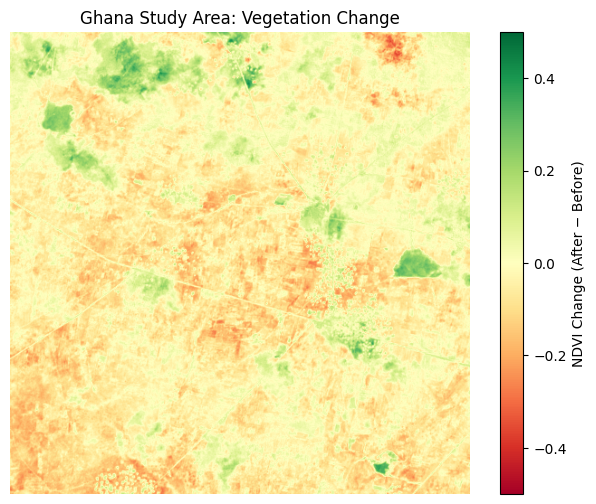

In [111]:
import matplotlib.pyplot as plt

ndvi_change_aoi = ndvi_after_aoi - ndvi_before_aoi

plt.figure(figsize=(8, 6))
plt.imshow(
    ndvi_change_aoi,
    cmap="RdYlGn",
    vmin=-0.5,
    vmax=0.5
)
plt.colorbar(label="NDVI Change (After − Before)")
plt.title("Ghana Study Area: Vegetation Change")
plt.axis("off")
plt.show()

In [112]:
change = ndvi_after_aoi - ndvi_before_aoi

valid = np.isfinite(change)

decreased = (change < -0.05) & valid
stable = (change >= -0.05) & (change <= 0.05) & valid
increased = (change > 0.05) & valid

total = valid.sum()

print(f"Valid pixels: {total}")
print(f"NDVI decreased: {100 * decreased.sum() / total:.2f}%")
print(f"NDVI stable:    {100 * stable.sum() / total:.2f}%")
print(f"NDVI increased: {100 * increased.sum() / total:.2f}%")

Valid pixels: 259588
NDVI decreased: 40.89%
NDVI stable:    47.22%
NDVI increased: 11.89%


In [113]:
from pathlib import Path

dataset_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1"
)

label_files = list(
    (dataset_dir / "data" / "flood_events" / "HandLabeled" / "LabelHand")
    .rglob("*Ghana*103272*")
)

print("Matching label files:", len(label_files))

for f in label_files:
    print(f)

Matching label files: 1
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\LabelHand\Ghana_103272_LabelHand.tif


In [114]:
import rasterio
import numpy as np

label_path = label_files[0]

with rasterio.open(label_path) as src:
    flood_label = src.read(1)
    print("Label dimensions:", flood_label.shape)
    print("CRS:", src.crs)
    print("Pixel values:", np.unique(flood_label, return_counts=True))

Label dimensions: (512, 512)
CRS: EPSG:4326
Pixel values: (array([-1,  0,  1], dtype=int16), array([  2875, 257711,   1558]))


In [115]:
from rasterio.warp import reproject, Resampling
import rasterio
import numpy as np

with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    target_transform = src.transform
    target_crs = src.crs
    target_shape = (src.height, src.width)

aligned_label = np.full(
    target_shape, -1, dtype=np.int16
)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        resampling=Resampling.nearest,
        src_nodata=-1,
        dst_nodata=-1
    )

print("Aligned label shape:", aligned_label.shape)
print("Aligned label values and counts:",
      np.unique(aligned_label, return_counts=True))

Aligned label shape: (10980, 10980)
Aligned label values and counts: (array([-1,  0,  1], dtype=int16), array([120306153,    252727,      1520]))


In [119]:
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds
import rasterio
import numpy as np

with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    aoi_bounds = transform_bounds(
        "EPSG:4326", src.crs,
        -1.14984356, 9.42871722,
        -1.10384982, 9.47471096
    )

    window = from_bounds(*aoi_bounds, transform=src.transform)
    window = window.round_offsets().round_lengths()

label_crop = aligned_label[
    int(window.row_off):int(window.row_off + window.height),
    int(window.col_off):int(window.col_off + window.width)
]

change_crop = ndvi_after_aoi - ndvi_before_aoi

print("Label crop shape:", label_crop.shape)
print("NDVI change shape:", change_crop.shape)

Label crop shape: (511, 508)
NDVI change shape: (511, 508)


In [120]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.transform import from_bounds

# Use the before-image band as the target grid
with rasterio.open(next(before_safe.rglob("*_B04_10m.jp2"))) as src:
    target_crs = src.crs
    target_transform = src.transform

# Exact Ghana chip bounds from the original label
with rasterio.open(label_path) as src:
    label_bounds = transform_bounds(
        src.crs, target_crs, *src.bounds
    )

# Create a target grid matching the NDVI AOI crop
height, width = ndvi_before_aoi.shape
left, bottom, right, top = label_bounds

crop_transform = from_bounds(
    left, bottom, right, top, width, height
)

aligned_label_aoi = np.full((height, width), -1, dtype=np.int16)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label_aoi,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=crop_transform,
        dst_crs=target_crs,
        src_nodata=-1,
        dst_nodata=-1,
        resampling=Resampling.nearest
    )

print("NDVI crop shape:", ndvi_before_aoi.shape)
print("Aligned label shape:", aligned_label_aoi.shape)
print("Label values:", np.unique(aligned_label_aoi, return_counts=True))

NDVI crop shape: (511, 508)
Aligned label shape: (511, 508)
Label values: (array([-1,  0,  1], dtype=int16), array([  5515, 252553,   1520]))


In [121]:
valid = (
    (aligned_label_aoi != -1)
    & np.isfinite(ndvi_before_aoi)
    & np.isfinite(ndvi_after_aoi)
)

water = aligned_label_aoi == 1
ndvi_decreased = (ndvi_after_aoi - ndvi_before_aoi) < -0.05

water_pixels = water & valid
overlap = water_pixels & ndvi_decreased

print("Valid pixels:", valid.sum())
print("Water-labelled pixels:", water_pixels.sum())
print("Water pixels with NDVI decline:", overlap.sum())

if water_pixels.sum() > 0:
    print(
        "Water pixels with NDVI decline:",
        f"{100 * overlap.sum() / water_pixels.sum():.2f}%"
    )

Valid pixels: 254073
Water-labelled pixels: 1520
Water pixels with NDVI decline: 8
Water pixels with NDVI decline: 0.53%


In [122]:
from pathlib import Path
import rasterio
import numpy as np

jrc_dir = (
    dataset_dir / "data" / "flood_events" /
    "HandLabeled" / "JRCWaterHand"
)

jrc_files = list(jrc_dir.rglob("*Ghana*103272*"))

print("Matching JRC files:", len(jrc_files))

for f in jrc_files:
    print(f)
    with rasterio.open(f) as src:
        arr = src.read(1)
        print("Shape:", arr.shape)
        print("Values and counts:", np.unique(arr, return_counts=True))

Matching JRC files: 1
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\data\flood_events\HandLabeled\JRCWaterHand\Ghana_103272_JRCWaterHand.tif
Shape: (512, 512)
Values and counts: (array([0, 1], dtype=uint8), array([261712,    432]))


In [123]:
import numpy as np
import rasterio

with rasterio.open(label_path) as src:
    label = src.read(1)

with rasterio.open(jrc_files[0]) as src:
    jrc = src.read(1)

three_class = np.zeros_like(label, dtype=np.uint8)

# Event/non-permanent water
three_class[label == 1] = 2

# Permanent water
three_class[(label == 1) & (jrc == 1)] = 1

# NoData
three_class[label == -1] = 255

values, counts = np.unique(three_class, return_counts=True)

for value, count in zip(values, counts):
    names = {0: "Land/not water", 1: "Permanent water", 2: "Event/non-permanent water", 255: "NoData"}
    print(f"{value} ({names.get(value, 'Unknown')}): {count} pixels")

0 (Land/not water): 257711 pixels
1 (Permanent water): 375 pixels
2 (Event/non-permanent water): 1183 pixels
255 (NoData): 2875 pixels


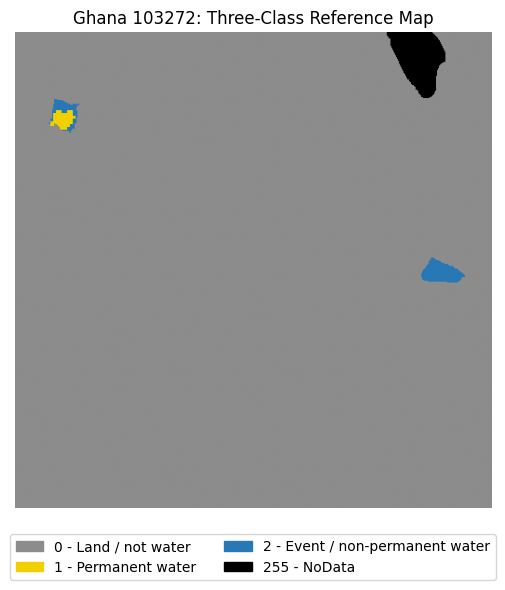

In [124]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np

display_map = three_class.astype(float)
display_map[three_class == 255] = np.nan

cmap = ListedColormap(["#8c8c8c", "#f0d000", "#2878b5"])
cmap.set_bad("black")

plt.figure(figsize=(7, 6))
plt.imshow(display_map, cmap=cmap, vmin=0, vmax=2)
plt.title("Ghana 103272: Three-Class Reference Map")
plt.axis("off")
plt.legend(
    handles=[
        Patch(color="#8c8c8c", label="0 - Land / not water"),
        Patch(color="#f0d000", label="1 - Permanent water"),
        Patch(color="#2878b5", label="2 - Event / non-permanent water"),
        Patch(color="black", label="255 - NoData"),
    ],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2
)
plt.tight_layout()
plt.show()

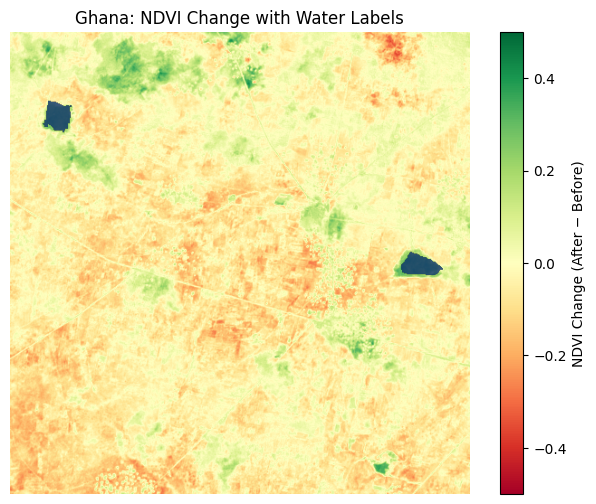

NDVI shape: (511, 508)
Label shape: (511, 508)
Water-labelled pixels: 1516


In [126]:
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# Get the exact grid used by the cropped NDVI image
red_file = next(before_safe.rglob("*_B04_10m.jp2"))

with rasterio.open(red_file) as src:
    projected_bounds = transform_bounds(
        "EPSG:4326",
        src.crs,
        -1.14984356, 9.42871722,
        -1.10384982, 9.47471096
    )

    window = from_bounds(
        *projected_bounds,
        transform=src.transform
    ).round_offsets().round_lengths()

    target_transform = src.window_transform(window)
    target_crs = src.crs

height, width = ndvi_before_aoi.shape
aligned_label_aoi = np.full((height, width), -1, dtype=np.int16)

with rasterio.open(label_path) as src:
    reproject(
        source=rasterio.band(src, 1),
        destination=aligned_label_aoi,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        src_nodata=-1,
        dst_nodata=-1,
        resampling=Resampling.nearest
    )

# Plot NDVI change and water labels together
change = ndvi_after_aoi - ndvi_before_aoi
water_mask = np.ma.masked_where(
    aligned_label_aoi != 1,
    np.ones_like(aligned_label_aoi, dtype=float)
)

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(change, cmap="RdYlGn", vmin=-0.5, vmax=0.5)
ax.imshow(water_mask, cmap="Blues", vmin=0, vmax=1, alpha=0.8)
ax.set_title("Ghana: NDVI Change with Water Labels")
ax.axis("off")
fig.colorbar(im, ax=ax, label="NDVI Change (After − Before)")
plt.show()

print("NDVI shape:", change.shape)
print("Label shape:", aligned_label_aoi.shape)
print("Water-labelled pixels:", np.sum(aligned_label_aoi == 1))

In [128]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling, transform_bounds
from rasterio.windows import from_bounds

def calculate_mndwi(folder):
    green_file = next(folder.rglob("*_B03_10m.jp2"))
    swir_file = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(green_file) as green_src:
        bounds = transform_bounds(
            "EPSG:4326",
            green_src.crs,
            -1.14984356, 9.42871722,
            -1.10384982, 9.47471096
        )

        window = from_bounds(*bounds, transform=green_src.transform)
        window = window.round_offsets().round_lengths()

        green = green_src.read(1, window=window).astype(np.float32)
        target_transform = green_src.window_transform(window)
        target_crs = green_src.crs

    with rasterio.open(swir_file) as swir_src:
        swir = np.full(green.shape, np.nan, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=target_transform,
            dst_crs=target_crs,
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    denominator = green + swir
    mndwi = np.full(green.shape, np.nan, dtype=np.float32)

    valid = np.isfinite(green) & np.isfinite(swir) & (denominator != 0)
    mndwi[valid] = (green[valid] - swir[valid]) / denominator[valid]

    return mndwi

mndwi_before = calculate_mndwi(before_safe)
mndwi_after = calculate_mndwi(after_safe)

print("Before MNDWI mean:", np.nanmean(mndwi_before))
print("After MNDWI mean:", np.nanmean(mndwi_after))
print("MNDWI change:", np.nanmean(mndwi_after - mndwi_before))
print("Shapes:", mndwi_before.shape, mndwi_after.shape)

Before MNDWI mean: -0.2710101
After MNDWI mean: -0.22712487
MNDWI change: 0.04388522
Shapes: (511, 508) (511, 508)


In [129]:
valid = np.isfinite(mndwi_before) & np.isfinite(mndwi_after)

water_before = (mndwi_before > 0) & valid
water_after = (mndwi_after > 0) & valid

count_before = water_before.sum()
count_after = water_after.sum()

total = valid.sum()

print("Valid pixels:", total)
print("Water-index pixels before:", count_before)
print("Water-index pixels after:", count_after)
print("Pixel-count change:", int(count_after - count_before))

if count_before > 0:
    print(
        "Relative change (%):",
        round(100 * (count_after - count_before) / count_before, 2)
    )

print("Before water-index area (km²):", round(count_before * 0.0001, 4))
print("After water-index area (km²):", round(count_after * 0.0001, 4))

Valid pixels: 259588
Water-index pixels before: 2281
Water-index pixels after: 510
Pixel-count change: -1771
Relative change (%): -77.64
Before water-index area (km²): 0.2281
After water-index area (km²): 0.051


C:\Users\GNANA SRIHASA\AppData\Local\Temp\ipykernel_27864\2183348941.py:18: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


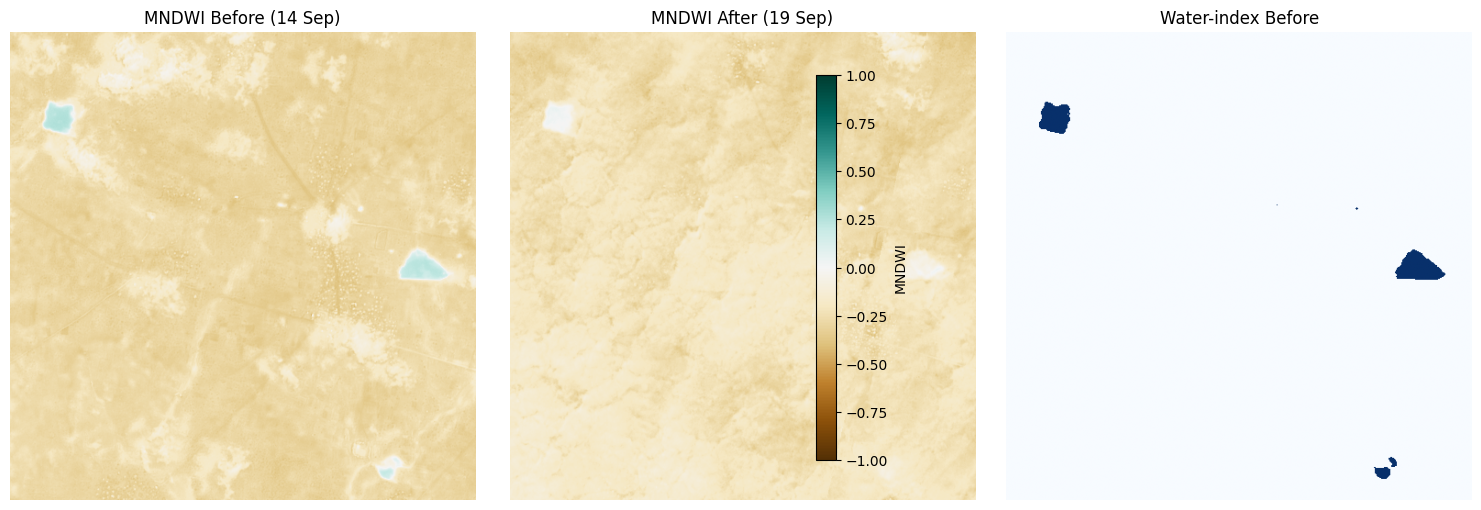

In [130]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

im0 = axes[0].imshow(mndwi_before, cmap="BrBG", vmin=-1, vmax=1)
axes[0].set_title("MNDWI Before (14 Sep)")
axes[0].axis("off")

im1 = axes[1].imshow(mndwi_after, cmap="BrBG", vmin=-1, vmax=1)
axes[1].set_title("MNDWI After (19 Sep)")
axes[1].axis("off")

axes[2].imshow(water_before, cmap="Blues", vmin=0, vmax=1)
axes[2].set_title("Water-index Before")
axes[2].axis("off")

fig.colorbar(im1, ax=axes[:2], label="MNDWI")
plt.tight_layout()
plt.show()

In [131]:
water_ref = aligned_label_aoi == 1

print("Reference water pixels:", water_ref.sum())

print(
    "Before MNDWI at reference water:",
    np.nanmean(mndwi_before[water_ref])
)

print(
    "After MNDWI at reference water:",
    np.nanmean(mndwi_after[water_ref])
)

print(
    "Before above zero:",
    np.sum((mndwi_before > 0) & water_ref)
)

print(
    "After above zero:",
    np.sum((mndwi_after > 0) & water_ref)
)

Reference water pixels: 1516
Before MNDWI at reference water: 0.20513771
After MNDWI at reference water: -0.030356448
Before above zero: 1469
After above zero: 507


In [132]:
water_ref = (aligned_label_aoi == 1)

valid_ref = (
    water_ref
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

before_positive = mndwi_before > 0
after_positive = mndwi_after > 0

both_positive = valid_ref & before_positive & after_positive
lost_positive = valid_ref & before_positive & ~after_positive
gained_positive = valid_ref & ~before_positive & after_positive
both_negative = valid_ref & ~before_positive & ~after_positive

total = valid_ref.sum()

print("Valid reference-water pixels:", total)
print("Positive on both dates:", both_positive.sum())
print("Positive before, negative after:", lost_positive.sum())
print("Negative before, positive after:", gained_positive.sum())
print("Negative on both dates:", both_negative.sum())
print("Total check:", both_positive.sum() + lost_positive.sum()
      + gained_positive.sum() + both_negative.sum())

Valid reference-water pixels: 1516
Positive on both dates: 507
Positive before, negative after: 962
Negative before, positive after: 0
Negative on both dates: 47
Total check: 1516


In [133]:
scl_files = list(after_safe.rglob("*_SCL_20m.jp2"))

print("SCL files found:", len(scl_files))

for f in scl_files:
    print(f.name)

SCL files found: 1
T30PXR_20180919T102021_SCL_20m.jp2


In [134]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

scl_file = scl_files[0]

with rasterio.open(scl_file) as src:
    scl = np.zeros(mndwi_after.shape, dtype=np.uint8)

    reproject(
        source=rasterio.band(src, 1),
        destination=scl,
        src_transform=src.transform,
        src_crs=src.crs,
        dst_transform=target_transform,
        dst_crs=target_crs,
        resampling=Resampling.nearest
    )

values, counts = np.unique(scl, return_counts=True)

scl_names = {
    0: "No data",
    1: "Saturated/defective",
    2: "Dark area pixels",
    3: "Cloud shadows",
    4: "Vegetation",
    5: "Bare soil",
    6: "Water",
    7: "Unclassified",
    8: "Cloud, medium probability",
    9: "Cloud, high probability",
    10: "Cirrus",
    11: "Snow/ice"
}

for value, count in zip(values, counts):
    print(f"{value} ({scl_names.get(value, 'Unknown')}): {count}")

4 (Vegetation): 143240
5 (Bare soil): 29672
6 (Water): 172
7 (Unclassified): 1776
8 (Cloud, medium probability): 1106
9 (Cloud, high probability): 16
10 (Cirrus): 83606


In [135]:
# Exclude no-data, cloud shadows, medium/high-probability clouds,
# cirrus, and saturated/defective pixels.
clear_after = ~np.isin(scl, [0, 1, 3, 8, 9, 10, 11])

valid_clear = (
    clear_after
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

print("Total study pixels:", scl.size)
print("Clear pixels retained:", valid_clear.sum())
print("Excluded pixels:", (~clear_after).sum())

before_clear_mean = np.mean(mndwi_before[valid_clear])
after_clear_mean = np.mean(mndwi_after[valid_clear])

water_before_clear = np.sum(
    (mndwi_before > 0) & valid_clear
)
water_after_clear = np.sum(
    (mndwi_after > 0) & valid_clear
)

print("Before clear-pixel MNDWI mean:", before_clear_mean)
print("After clear-pixel MNDWI mean:", after_clear_mean)
print("Before water-index pixels:", water_before_clear)
print("After water-index pixels:", water_after_clear)

Total study pixels: 259588
Clear pixels retained: 174860
Excluded pixels: 84728
Before clear-pixel MNDWI mean: -0.27147666
After clear-pixel MNDWI mean: -0.24708897
Before water-index pixels: 1333
After water-index pixels: 419


In [136]:
before_scl_files = list(before_safe.rglob("*_SCL_20m.jp2"))

print("Before SCL files found:", len(before_scl_files))

for f in before_scl_files:
    print(f.name)

Before SCL files found: 1
T30PXR_20180914T102019_SCL_20m.jp2


In [137]:
import rasterio
import numpy as np
from rasterio.warp import reproject, Resampling

def read_scl_on_aoi(scl_path):
    with rasterio.open(scl_path) as src:
        scl_aoi = np.zeros(mndwi_before.shape, dtype=np.uint8)

        reproject(
            source=rasterio.band(src, 1),
            destination=scl_aoi,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=target_transform,
            dst_crs=target_crs,
            resampling=Resampling.nearest
        )

    return scl_aoi

scl_before = read_scl_on_aoi(before_scl_files[0])
scl_after = read_scl_on_aoi(scl_files[0])

# Exclude no-data, defective pixels, cloud shadows, clouds, cirrus, snow/ice
bad_classes = [0, 1, 3, 8, 9, 10, 11]

clear_before = ~np.isin(scl_before, bad_classes)
clear_after = ~np.isin(scl_after, bad_classes)

shared_clear = (
    clear_before
    & clear_after
    & np.isfinite(mndwi_before)
    & np.isfinite(mndwi_after)
)

print("Total pixels:", shared_clear.size)
print("Clear on both dates:", shared_clear.sum())
print("Excluded on either date:", (~shared_clear).sum())

Total pixels: 259588
Clear on both dates: 163226
Excluded on either date: 96362


In [138]:
water_before_shared = (mndwi_before > 0) & shared_clear
water_after_shared = (mndwi_after > 0) & shared_clear

before_count = water_before_shared.sum()
after_count = water_after_shared.sum()

print("Shared clear pixels:", shared_clear.sum())
print("Water-index pixels before:", before_count)
print("Water-index pixels after:", after_count)
print("Pixel-count change:", int(after_count - before_count))

if before_count > 0:
    print(
        "Relative change (%):",
        round(100 * (after_count - before_count) / before_count, 2)
    )

print(
    "Before MNDWI mean:",
    np.mean(mndwi_before[shared_clear])
)
print(
    "After MNDWI mean:",
    np.mean(mndwi_after[shared_clear])
)

Shared clear pixels: 163226
Water-index pixels before: 1286
Water-index pixels after: 414
Pixel-count change: -872
Relative change (%): -67.81
Before MNDWI mean: -0.2766314
After MNDWI mean: -0.24716096


In [139]:
scl_water_before = (scl_before == 6) & shared_clear
scl_water_after = (scl_after == 6) & shared_clear

print("SCL water pixels before:", scl_water_before.sum())
print("SCL water pixels after:", scl_water_after.sum())

print(
    "MNDWI and SCL agree before:",
    np.sum(water_before_shared & scl_water_before)
)
print(
    "MNDWI and SCL agree after:",
    np.sum(water_after_shared & scl_water_after)
)

SCL water pixels before: 168
SCL water pixels after: 168
MNDWI and SCL agree before: 168
MNDWI and SCL agree after: 132


In [186]:
# Check whether before/after images and masks have matching shapes

arrays = {
    "NDVI before": ndvi_before_aoi,
    "NDVI after": ndvi_after_aoi,
    "MNDWI before": mndwi_before,
    "MNDWI after": mndwi_after,
    "Shared clear mask": shared_clear
}

for name, arr in arrays.items():
    print(f"{name}: {arr.shape}")

shapes_match = len(set(arr.shape for arr in arrays.values())) == 1
print("\nAll shapes match:", shapes_match)

NDVI before: (511, 508)
NDVI after: (511, 508)
MNDWI before: (511, 508)
MNDWI after: (511, 508)
Shared clear mask: (511, 508)

All shapes match: True


In [203]:
from pathlib import Path
import rasterio

# Use the folder paths directly
before_safe = Path(before_folder)
after_safe = Path(after_folder)

before_files = list(before_safe.rglob("*_B03_10m.jp2"))
after_files = list(after_safe.rglob("*_B03_10m.jp2"))

print("Before B03 files found:", len(before_files))
print("After B03 files found:", len(after_files))

if not before_files or not after_files:
    print("B03 files not found. Check the folder paths.")
else:
    for name, path in [
        ("Before", before_files[0]),
        ("After", after_files[0])
    ]:
        with rasterio.open(path) as src:
            print(f"\n{name} image")
            print("File:", path)
            print("CRS:", src.crs)
            print("Resolution:", src.res)
            print("Dimensions:", (src.height, src.width))
            print("Bounds:", src.bounds)
            print("Transform:", src.transform)

Before B03 files found: 1
After B03 files found: 1

Before image
File: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\Before\Sentinel-2\S2B_MSIL2A_20180914T102019_N0500_R065_T30PXR_20230802T150253.SAFE\GRANULE\L2A_T30PXR_A007956_20180914T102951\IMG_DATA\R10m\T30PXR_20180914T102019_B03_10m.jp2
CRS: EPSG:32630
Resolution: (10.0, 10.0)
Dimensions: (10980, 10980)
Bounds: BoundingBox(left=600000.0, bottom=990240.0, right=709800.0, top=1100040.0)
Transform: | 10.00, 0.00, 600000.00|
| 0.00,-10.00, 1100040.00|
| 0.00, 0.00, 1.00|

After image
File: C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\Objective1_Multitemporal\After\Sentinel-2\S2A_MSIL2A_20180919T102021_N0500_R065_T30PXR_20230824T111443.SAFE\GRANULE\L2A_T30PXR_A016936_20180919T102850\IMG_DATA\R10m\T30PXR_20180919T102021_B03_10m.jp2
CRS: EPSG:32630
Resolution: (10.0, 10.0)
Dimensions: (10980, 10980)
Bounds: BoundingBox(left=600000.0, bottom=990240.0, right=709800.0, top=1100040.0)
Transform: | 10.00, 0.00,

In [204]:
# Check which crop transforms exist in the notebook
for name in [
    "transform_before",
    "transform_after",
    "before_transform",
    "after_transform",
    "ndvi_before_transform",
    "ndvi_after_transform"
]:
    print(name, "exists:", name in globals())

transform_before exists: False
transform_after exists: False
before_transform exists: False
after_transform exists: False
ndvi_before_transform exists: False
ndvi_after_transform exists: False


In [205]:
import numpy as np

# Classify water pixels using MNDWI
water_before = (mndwi_before > 0) & shared_clear
water_after = (mndwi_after > 0) & shared_clear

# Count classified pixels
print("Before water pixels:", np.sum(water_before))
print("After water pixels:", np.sum(water_after))

# Estimate water area (each pixel is 10 m × 10 m = 100 m²)
pixel_area_m2 = 100

before_area_ha = np.sum(water_before) * pixel_area_m2 / 10000
after_area_ha = np.sum(water_after) * pixel_area_m2 / 10000

print(f"Before water area: {before_area_ha:.2f} hectares")
print(f"After water area: {after_area_ha:.2f} hectares")

Before water pixels: 1286
After water pixels: 414
Before water area: 12.86 hectares
After water area: 4.14 hectares


In [206]:
import rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

# Your AOI in longitude/latitude (EPSG:4326)
aoi_bounds = (-1.14984356, 9.42871722, -1.10384982, 9.47471096)

for name, folder in [
    ("Before", before_folder),
    ("After", after_folder)
]:
    band_path = next(Path(folder).rglob("*_B03_10m.jp2"))

    with rasterio.open(band_path) as src:
        bounds_utm = transform_bounds(
            "EPSG:4326", src.crs, *aoi_bounds
        )

        window = from_bounds(*bounds_utm, transform=src.transform)
        crop_transform = src.window_transform(window)

        print(f"\n{name} AOI crop")
        print("Crop dimensions:", (round(window.height), round(window.width)))
        print("Crop transform:", crop_transform)


Before AOI crop
Crop dimensions: (511, 508)
Crop transform: | 10.00, 0.00, 703119.64|
| 0.00,-10.00, 1047902.76|
| 0.00, 0.00, 1.00|

After AOI crop
Crop dimensions: (511, 508)
Crop transform: | 10.00, 0.00, 703119.64|
| 0.00,-10.00, 1047902.76|
| 0.00, 0.00, 1.00|


In [207]:
from pathlib import Path

for name, folder in [
    ("Before", before_folder),
    ("After", after_folder)
]:
    b08 = list(Path(folder).rglob("*_B08_10m.jp2"))
    b11 = list(Path(folder).rglob("*_B11_20m.jp2"))

    print(f"\n{name} image")
    print("B08 (NIR) files found:", len(b08))
    print("B11 (SWIR) files found:", len(b11))


Before image
B08 (NIR) files found: 1
B11 (SWIR) files found: 1

After image
B08 (NIR) files found: 1
B11 (SWIR) files found: 1


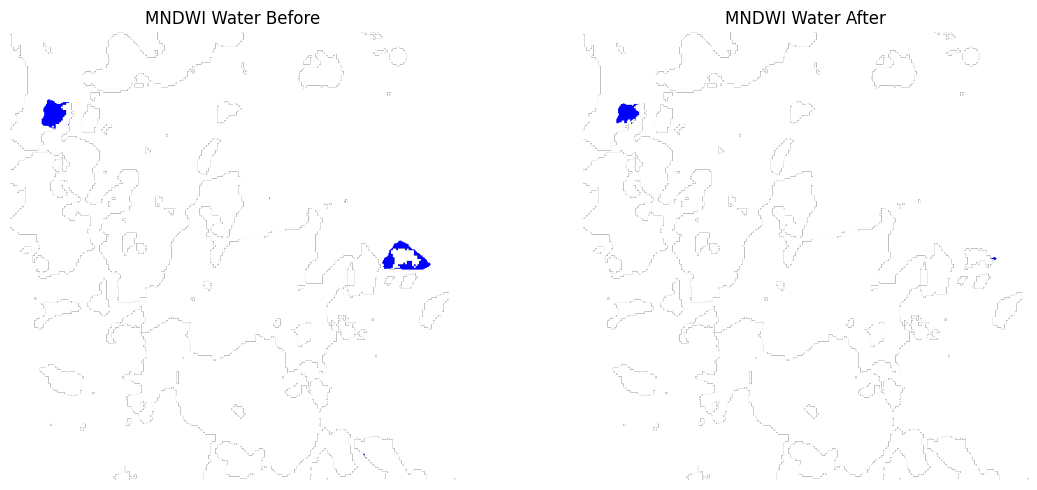

In [140]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(
    np.where(shared_clear, water_before_shared, np.nan),
    cmap=ListedColormap(["white", "blue"]),
    vmin=0, vmax=1
)
axes[0].set_title("MNDWI Water Before")
axes[0].axis("off")

axes[1].imshow(
    np.where(shared_clear, water_after_shared, np.nan),
    cmap=ListedColormap(["white", "blue"]),
    vmin=0, vmax=1
)
axes[1].set_title("MNDWI Water After")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [141]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Compare only clear pixels with valid reference labels
evaluation_mask = (
    shared_clear
    & (aligned_label_aoi != -1)
)

y_true = (aligned_label_aoi[evaluation_mask] == 1).astype(int)
y_pred = (mndwi_after[evaluation_mask] > 0).astype(int)

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Not labelled water", "Labelled water"],
    zero_division=0
))

Confusion matrix:
[[158192      1]
 [   487    413]]

Classification report:
                    precision    recall  f1-score   support

Not labelled water       1.00      1.00      1.00    158193
    Labelled water       1.00      0.46      0.63       900

          accuracy                           1.00    159093
         macro avg       1.00      0.73      0.81    159093
      weighted avg       1.00      1.00      1.00    159093



In [142]:
from sklearn.metrics import jaccard_score, f1_score

print(
    "Water IoU:",
    round(jaccard_score(y_true, y_pred, pos_label=1), 4)
)

print(
    "Water Dice/F1:",
    round(f1_score(y_true, y_pred, pos_label=1), 4)
)

Water IoU: 0.4584
Water Dice/F1: 0.6286


In [209]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
from shapely.geometry import box, mapping
from rasterio.warp import transform_bounds

def calculate_ndbi(folder):
    folder = Path(folder)

    b08_path = next(folder.rglob("*_B08_10m.jp2"))
    b11_path = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(b08_path) as nir_src, rasterio.open(b11_path) as swir_src:
        nir = nir_src.read(1).astype(np.float32)
        swir = np.zeros(nir.shape, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=nir_src.transform,
            dst_crs=nir_src.crs,
            resampling=Resampling.bilinear
        )

        # Crop both bands to the AOI
        aoi_utm = transform_bounds(
            "EPSG:4326", nir_src.crs, *aoi_bounds
        )
        geom = [mapping(box(*aoi_utm))]

        nir_crop, crop_transform = mask(
            nir_src, geom, crop=True, filled=False
        )

        swir_crop, _ = mask(
            rasterio.io.MemoryFile().open(), geom, crop=True
        ) if False else (None, None)

        # Crop resampled SWIR using the same pixel window
        from rasterio.windows import from_bounds
        window = from_bounds(*aoi_utm, transform=nir_src.transform)
        window = window.round_offsets().round_lengths()

        nir_crop = nir_src.read(1, window=window).astype(np.float32)
        swir_crop = swir[
            int(window.row_off):int(window.row_off + window.height),
            int(window.col_off):int(window.col_off + window.width)
        ]

        nir_crop[nir_crop == 0] = np.nan
        swir_crop[swir_crop == 0] = np.nan

        denominator = swir_crop + nir_crop
        ndbi = np.divide(
            swir_crop - nir_crop,
            denominator,
            out=np.full_like(denominator, np.nan),
            where=denominator != 0
        )

        return ndbi

ndbi_before = calculate_ndbi(before_folder)
ndbi_after = calculate_ndbi(after_folder)

print("NDBI before shape:", ndbi_before.shape)
print("NDBI after shape:", ndbi_after.shape)
print("Mean NDBI before:", np.nanmean(ndbi_before))
print("Mean NDBI after:", np.nanmean(ndbi_after))

NDBI before shape: (511, 508)
NDBI after shape: (511, 508)
Mean NDBI before: -0.09127111
Mean NDBI after: -0.1009015


In [210]:
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.mask import mask
from shapely.geometry import box, mapping
from rasterio.warp import transform_bounds

def calculate_ndbi(folder):
    folder = Path(folder)

    b08_path = next(folder.rglob("*_B08_10m.jp2"))
    b11_path = next(folder.rglob("*_B11_20m.jp2"))

    with rasterio.open(b08_path) as nir_src, rasterio.open(b11_path) as swir_src:
        nir = nir_src.read(1).astype(np.float32)
        swir = np.zeros(nir.shape, dtype=np.float32)

        reproject(
            source=rasterio.band(swir_src, 1),
            destination=swir,
            src_transform=swir_src.transform,
            src_crs=swir_src.crs,
            dst_transform=nir_src.transform,
            dst_crs=nir_src.crs,
            resampling=Resampling.bilinear
        )

        # Crop both bands to the AOI
        aoi_utm = transform_bounds(
            "EPSG:4326", nir_src.crs, *aoi_bounds
        )
        geom = [mapping(box(*aoi_utm))]

        nir_crop, crop_transform = mask(
            nir_src, geom, crop=True, filled=False
        )

        swir_crop, _ = mask(
            rasterio.io.MemoryFile().open(), geom, crop=True
        ) if False else (None, None)

        # Crop resampled SWIR using the same pixel window
        from rasterio.windows import from_bounds
        window = from_bounds(*aoi_utm, transform=nir_src.transform)
        window = window.round_offsets().round_lengths()

        nir_crop = nir_src.read(1, window=window).astype(np.float32)
        swir_crop = swir[
            int(window.row_off):int(window.row_off + window.height),
            int(window.col_off):int(window.col_off + window.width)
        ]

        nir_crop[nir_crop == 0] = np.nan
        swir_crop[swir_crop == 0] = np.nan

        denominator = swir_crop + nir_crop
        ndbi = np.divide(
            swir_crop - nir_crop,
            denominator,
            out=np.full_like(denominator, np.nan),
            where=denominator != 0
        )

        return ndbi

ndbi_before = calculate_ndbi(before_folder)
ndbi_after = calculate_ndbi(after_folder)

print("NDBI before shape:", ndbi_before.shape)
print("NDBI after shape:", ndbi_after.shape)
print("Mean NDBI before:", np.nanmean(ndbi_before))
print("Mean NDBI after:", np.nanmean(ndbi_after))

NDBI before shape: (511, 508)
NDBI after shape: (511, 508)
Mean NDBI before: -0.09127111
Mean NDBI after: -0.1009015


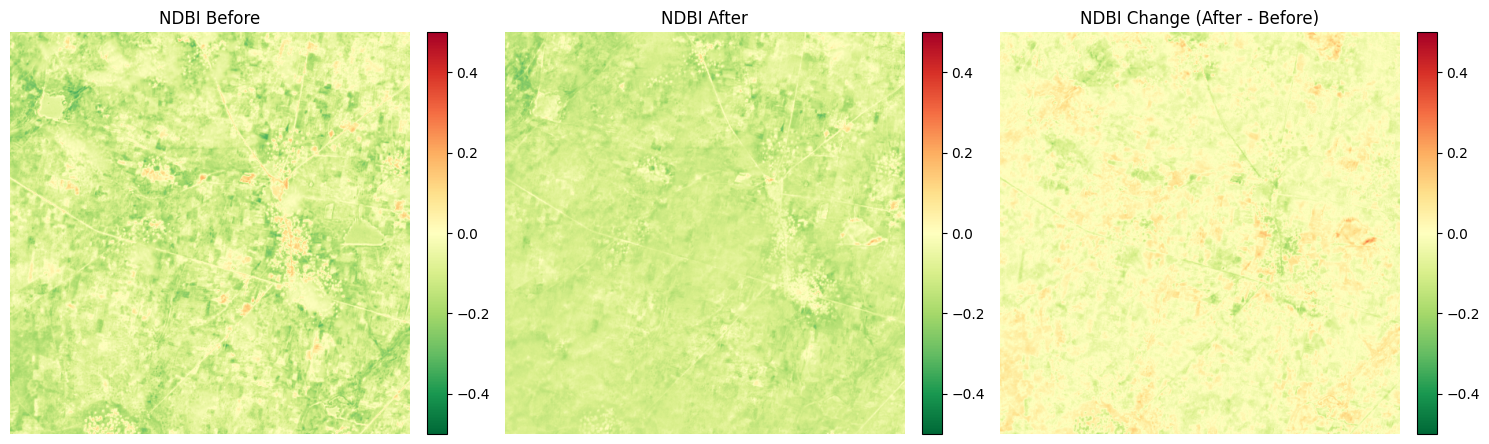

In [212]:
import matplotlib.pyplot as plt
import numpy as np

ndbi_change = ndbi_after - ndbi_before

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    (ndbi_before, "NDBI Before"),
    (ndbi_after, "NDBI After"),
    (ndbi_change, "NDBI Change (After - Before)")
]

for ax, (data, title) in zip(axes, images):
    im = ax.imshow(data, cmap="RdYlGn_r", vmin=-0.5, vmax=0.5)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

In [143]:
import pandas as pd
from pathlib import Path

split_dir = dataset_dir / "splits" / "flood_handlabeled"

for csv_file in split_dir.glob("*.csv"):
    df = pd.read_csv(csv_file)

    matches = df[
        df.astype(str).apply(
            lambda col: col.str.contains("Ghana_103272", case=False, na=False)
        ).any(axis=1)
    ]

    if not matches.empty:
        print(f"\nFile: {csv_file.name}")
        display(matches)

In [144]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1"
)

print("Project folder exists:", project_dir.exists())

print("\nTop-level folders and files:")
for item in project_dir.iterdir():
    print(item.name)

Project folder exists: True

Top-level folders and files:
Augmented_Labels
Augmented_S1
catalog
catalog.zip
checkpoints
data
Objective1_Multitemporal
Sen1Floods11_Metadata.geojson
splits


In [168]:
from pathlib import Path

checkpoint_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\checkpoints"
)

print("Checkpoints folder exists:", checkpoint_dir.exists())

for f in checkpoint_dir.rglob("*"):
    if f.is_file():
        print(f.name, "|", round(f.stat().st_size / (1024 * 1024), 2), "MB")

Checkpoints folder exists: True
5e4_flood_0_89_0.5418742895126343.cp | 125.71 MB
5e4_handlabeled_0_8_0.43163052201271057.cp | 125.71 MB
5e4_permanent_0_180_0.8432363867759705.cp | 125.71 MB
5e4_s1weak_2_3_0.45159465074539185.cp | 125.71 MB


In [169]:
import torch
from pathlib import Path

checkpoint_path = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\checkpoints\5e4_flood_0_89_0.5418742895126343.cp"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys()))

    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(key, "-> dictionary with", len(value), "entries")
        elif torch.is_tensor(value):
            print(key, "-> tensor", tuple(value.shape))
        else:
            print(key, "->", type(value).__name__)

Checkpoint type: <class 'collections.OrderedDict'>
Checkpoint keys: ['backbone.conv1.weight', 'backbone.bn1.weight', 'backbone.bn1.bias', 'backbone.layer1.0.conv1.weight', 'backbone.layer1.0.bn1.weight', 'backbone.layer1.0.bn1.bias', 'backbone.layer1.0.conv2.weight', 'backbone.layer1.0.bn2.weight', 'backbone.layer1.0.bn2.bias', 'backbone.layer1.0.conv3.weight', 'backbone.layer1.0.bn3.weight', 'backbone.layer1.0.bn3.bias', 'backbone.layer1.0.downsample.0.weight', 'backbone.layer1.0.downsample.1.weight', 'backbone.layer1.0.downsample.1.bias', 'backbone.layer1.1.conv1.weight', 'backbone.layer1.1.bn1.weight', 'backbone.layer1.1.bn1.bias', 'backbone.layer1.1.conv2.weight', 'backbone.layer1.1.bn2.weight', 'backbone.layer1.1.bn2.bias', 'backbone.layer1.1.conv3.weight', 'backbone.layer1.1.bn3.weight', 'backbone.layer1.1.bn3.bias', 'backbone.layer1.2.conv1.weight', 'backbone.layer1.2.bn1.weight', 'backbone.layer1.2.bn1.bias', 'backbone.layer1.2.conv2.weight', 'backbone.layer1.2.bn2.weight', 'ba

In [145]:
from pathlib import Path
import torch

checkpoint_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\checkpoints"
)

for path in checkpoint_dir.glob("*.cp"):
    state = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    print(f"\n{path.name}")
    print("Input weights:", tuple(state["backbone.conv1.weight"].shape))
    print("Output weights:", tuple(state["classifier.4.weight"].shape))


5e4_flood_0_89_0.5418742895126343.cp
Input weights: (64, 2, 7, 7)
Output weights: (2, 512, 1, 1)

5e4_handlabeled_0_8_0.43163052201271057.cp
Input weights: (64, 2, 7, 7)
Output weights: (2, 512, 1, 1)

5e4_permanent_0_180_0.8432363867759705.cp
Input weights: (64, 2, 7, 7)
Output weights: (2, 512, 1, 1)

5e4_s1weak_2_3_0.45159465074539185.cp
Input weights: (64, 2, 7, 7)
Output weights: (2, 512, 1, 1)


In [146]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1"
)

keywords = [
    "5e4_flood",
    "DeepLab",
    "deeplab",
    "classifier.4",
    "handlabeled",
    "s1weak"
]

for path in project_dir.rglob("*.py"):
    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
        found = [word for word in keywords if word in content]

        if found:
            print(f"\nFile: {path}")
            print("Matches:", ", ".join(found))
    except OSError:
        pass

In [147]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1"
)

for pattern in ["*.ipynb", "*.yaml", "*.yml", "*.json", "*.txt"]:
    files = list(project_dir.rglob(pattern))
    print(f"\n{pattern}: {len(files)} files")

    for path in files[:10]:
        print(path)


*.ipynb: 0 files

*.yaml: 0 files

*.yml: 0 files

*.json: 9665 files
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\catalog.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_hand_labeled_label\collection.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_hand_labeled_source\collection.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_weak_labeled_label\collection.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_weak_labeled_source\collection.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_weak_labeled_source\Bolivia_1009032\Bolivia_1009032.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_weak_labeled_source\Bolivia_1027817\Bolivia_1027817.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog\sen1floods11_weak_labeled_source\Bolivia_1037580\Bolivia_1037580.json
C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\catalog

In [148]:
from pathlib import Path

checkpoint_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1\checkpoints"
)

for path in checkpoint_dir.iterdir():
    print(path.name)

5e4_flood_0_89_0.5418742895126343.cp
5e4_handlabeled_0_8_0.43163052201271057.cp
5e4_permanent_0_180_0.8432363867759705.cp
5e4_s1weak_2_3_0.45159465074539185.cp


In [149]:
from pathlib import Path

dataset_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\Sen1Floods11\v1.1"
)

for path in dataset_dir.rglob("*.pth"):
    print(path)

In [150]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI"
)

for path in project_dir.rglob("*.ipynb"):
    print(path)

C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\major_project.ipynb
C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\.ipynb_checkpoints\major_project-checkpoint.ipynb


In [151]:
from pathlib import Path

project_dir = Path.cwd()

for name in ["unet_10epoch.pth", "unet_10epoch_new.pth"]:
    path = project_dir / name
    print(name, "exists:", path.exists())
    if path.exists():
        print("Size (MB):", round(path.stat().st_size / (1024 * 1024), 2))

unet_10epoch.pth exists: True
Size (MB): 7.36
unet_10epoch_new.pth exists: True
Size (MB): 7.36


In [152]:
import torch

print("PyTorch:", torch.__version__)

try:
    import transformers
    print("Transformers:", transformers.__version__)
except ImportError:
    print("Transformers is not installed")

PyTorch: 2.14.1+cpu


C:\Users\GNANA SRIHASA\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformers: 5.19.0


In [153]:
import torch
from transformers import SegformerConfig, SegformerForSemanticSegmentation

config = SegformerConfig(
    num_channels=2,
    num_labels=3,
    num_encoder_blocks=4,
    depths=[2, 2, 2, 2],
    hidden_sizes=[32, 64, 160, 256],
    num_attention_heads=[1, 2, 5, 8],
    patch_sizes=[7, 3, 3, 3],
    strides=[4, 2, 2, 2],
    sr_ratios=[8, 4, 2, 1],
    decoder_hidden_size=128
)

segformer = SegformerForSemanticSegmentation(config)
device = torch.device("cpu")
segformer = segformer.to(device)

print("SegFormer created successfully")
print("Input channels:", config.num_channels)
print("Output classes:", config.num_labels)
print("Parameters:", sum(p.numel() for p in segformer.parameters()))

SegFormer created successfully
Input channels: 2
Output classes: 3
Parameters: 3450051


In [154]:
print("dataset_dir:", "dataset_dir" in globals())
print("train_loader:", "train_loader" in globals())
print("val_loader:", "val_loader" in globals())
print("test_loader:", "test_loader" in globals())
print("train_dataset:", "train_dataset" in globals())

dataset_dir: True
train_loader: True
val_loader: False
test_loader: False
train_dataset: True


In [155]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Label dtype:", labels.dtype)
print("Label values:", torch.unique(labels))

Images shape: torch.Size([4, 2, 512, 512])
Labels shape: torch.Size([4, 512, 512])
Image dtype: torch.float32
Label dtype: torch.int64
Label values: tensor([  0,   1,   2, 255])


In [156]:
import torch
import torch.nn.functional as F
from torch.optim import AdamW

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(segformer.parameters(), lr=1e-4)
segformer.train()

running_loss = 0.0

for step, (images, labels) in enumerate(train_loader):
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = segformer(pixel_values=images).logits
    outputs = F.interpolate(
        outputs,
        size=labels.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    loss = F.cross_entropy(outputs, labels, ignore_index=255)
    loss.backward()
    optimizer.step()

    running_loss += loss.item()

    if (step + 1) % 10 == 0:
        print(f"Batch {step + 1}: loss = {loss.item():.4f}")

    # Smoke test: stop after 10 batches
    if step + 1 >= 10:
        break

print("10-batch smoke test complete.")
print("Average loss:", running_loss / (step + 1))

Batch 10: loss = 1.0878
10-batch smoke test complete.
Average loss: 1.044055998325348


In [157]:
from pathlib import Path
import torch

save_path = Path.cwd() / "segformer_smoketest.pth"

torch.save(segformer.state_dict(), save_path)

print("Saved:", save_path)
print("Size (MB):", round(save_path.stat().st_size / (1024 * 1024), 2))

Saved: C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\segformer_smoketest.pth
Size (MB): 13.24


In [158]:
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "train", "valid", "val", "test", "loader", "dataset"
    ]):
        obj = globals()[name]
        if "loader" in name.lower() or "dataset" in name.lower():
            print(name, ":", type(obj).__name__)

AugmentedFloodDataset : type
DataLoader : type
Dataset : type
__loader__ : NoneType
dataset_dir : WindowsPath
dataset_root : WindowsPath
train_dataset : AugmentedFloodDataset
train_loader : DataLoader


In [159]:
import pandas as pd
from pathlib import Path

split_dir = dataset_dir / "splits" / "flood_handlabeled"

train_df = pd.read_csv(split_dir / "flood_train_data.csv", header=None)
valid_df = pd.read_csv(split_dir / "flood_valid_data.csv", header=None)
test_df  = pd.read_csv(split_dir / "flood_test_data.csv", header=None)

for name, df in [
    ("Train", train_df),
    ("Validation", valid_df),
    ("Test", test_df)
]:
    print(f"{name}: {len(df)} rows")
    print(df.head(2).to_string(index=False))
    print()

Train: 252 rows
                      0                          1
Ghana_103272_S1Hand.tif Ghana_103272_LabelHand.tif
 Ghana_24858_S1Hand.tif  Ghana_24858_LabelHand.tif

Validation: 89 rows
                      0                          1
  Ghana_5079_S1Hand.tif   Ghana_5079_LabelHand.tif
Ghana_895194_S1Hand.tif Ghana_895194_LabelHand.tif

Test: 90 rows
                       0                           1
 Ghana_313799_S1Hand.tif  Ghana_313799_LabelHand.tif
Ghana_1078550_S1Hand.tif Ghana_1078550_LabelHand.tif



In [160]:
train_df.columns = ["s1", "label"]
valid_df.columns = ["s1", "label"]
test_df.columns = ["s1", "label"]

print("Train columns:", train_df.columns.tolist())
print("Validation columns:", valid_df.columns.tolist())
print("Test columns:", test_df.columns.tolist())

print("\nValidation example:")
print(valid_df.iloc[0].to_dict())

Train columns: ['s1', 'label']
Validation columns: ['s1', 'label']
Test columns: ['s1', 'label']

Validation example:
{'s1': 'Ghana_5079_S1Hand.tif', 'label': 'Ghana_5079_LabelHand.tif'}


In [165]:

valid_dataset = AugmentedFloodDataset(
    valid_df, s1_folder, label_folder, jrc_folder,
    include_augmented=False
)

test_dataset = AugmentedFloodDataset(
    test_df, s1_folder, label_folder, jrc_folder,
    include_augmented=False
)

valid_loader = DataLoader(
    valid_dataset, batch_size=1, shuffle=False
)
test_loader = DataLoader(
    test_dataset, batch_size=1, shuffle=False
)

print("Validation samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))


Validation samples: 89
Test samples: 90


In [166]:
images, labels = next(iter(valid_loader))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Label values:", torch.unique(labels))

Image shape: torch.Size([1, 2, 512, 512])
Label shape: torch.Size([1, 512, 512])
Label values: tensor([255])


In [167]:
import numpy as np

for i in range(min(10, len(valid_dataset))):
    _, label = valid_dataset[i]
    values, counts = np.unique(
        label.numpy(), return_counts=True
    )

    valid_pixels = int((label != 255).sum())

    print(
        f"Sample {i}: valid pixels = {valid_pixels}, "
        f"labels = {dict(zip(values.tolist(), counts.tolist()))}"
    )

Sample 0: valid pixels = 0, labels = {255: 262144}
Sample 1: valid pixels = 252706, labels = {0: 244009, 2: 8697, 255: 9438}
Sample 2: valid pixels = 262144, labels = {0: 118093, 1: 6354, 2: 137697}
Sample 3: valid pixels = 262144, labels = {0: 262144}
Sample 4: valid pixels = 0, labels = {255: 262144}
Sample 5: valid pixels = 55761, labels = {0: 55761, 255: 206383}
Sample 6: valid pixels = 262144, labels = {0: 258185, 2: 3959}
Sample 7: valid pixels = 262144, labels = {0: 262144}
Sample 8: valid pixels = 233229, labels = {0: 136418, 1: 2440, 2: 94371, 255: 28915}
Sample 9: valid pixels = 0, labels = {255: 262144}


In [169]:
def count_usable_samples(dataset):
    empty = []
    usable = []

    for i in range(len(dataset)):
        _, label = dataset[i]
        valid_pixels = int((label != 255).sum())

        if valid_pixels == 0:
            empty.append(i)
        else:
            usable.append(i)

    return usable, empty


valid_usable, valid_empty = count_usable_samples(valid_dataset)
test_usable, test_empty = count_usable_samples(test_dataset)

print("Validation usable:", len(valid_usable))
print("Validation all-ignored:", len(valid_empty), valid_empty)

print("Test usable:", len(test_usable))
print("Test all-ignored:", len(test_empty), test_empty)

Validation usable: 86
Validation all-ignored: 3 [0, 4, 9]
Test usable: 89
Test all-ignored: 1 [8]


In [170]:
train_usable, train_empty = count_usable_samples(train_dataset)

print("Training samples:", len(train_dataset))
print("Training usable:", len(train_usable))
print("Training all-ignored:", len(train_empty))
print("All-ignored training indices:", train_empty)

Training samples: 486
Training usable: 485
Training all-ignored: 1
All-ignored training indices: [27]


In [171]:
import torch
import torch.nn.functional as F
from torch.optim import AdamW

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(
    segformer.parameters(),
    lr=1e-4
)

print("SegFormer ready for training")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(valid_dataset))
print("Test samples reserved for final evaluation:", len(test_dataset))

SegFormer ready for training
Training samples: 486
Validation samples: 89
Test samples reserved for final evaluation: 90


In [172]:

import torch
import torch.nn.functional as F
from torch.optim import AdamW
from pathlib import Path

device = torch.device("cpu")
segformer = segformer.to(device)

optimizer = AdamW(segformer.parameters(), lr=1e-4)
save_path = Path.cwd() / "segformer_best.pth"

def run_epoch(loader, training):
    segformer.train(training)
    total_loss = 0.0
    batches_used = 0
    skipped = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if not (labels != 255).any():
            skipped += 1
            continue

        with torch.set_grad_enabled(training):
            logits = segformer(pixel_values=images).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
            loss = F.cross_entropy(
                logits, labels, ignore_index=255
            )

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        total_loss += loss.item()
        batches_used += 1

    average_loss = (
        total_loss / batches_used if batches_used else float("nan")
    )
    return average_loss, batches_used, skipped

train_loss, train_batches, train_skipped = run_epoch(
    train_loader, training=True
)

val_loss, val_batches, val_skipped = run_epoch(
    valid_loader, training=False
)

print(f"Train loss: {train_loss:.4f}")
print(f"Validation loss: {val_loss:.4f}")
print(f"Training batches used: {train_batches}")
print(f"Validation batches used: {val_batches}")
print(f"Skipped all-ignored batches: {train_skipped + val_skipped}")

torch.save(segformer.state_dict(), save_path)
print("Saved checkpoint:", save_path)


Train loss: 0.8141
Validation loss: 0.3386
Training batches used: 122
Validation batches used: 86
Skipped all-ignored batches: 3
Saved checkpoint: C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\segformer_best.pth


In [201]:

from pathlib import Path
import torch

best_val_loss = float("inf")
best_path = Path.cwd() / "segformer_best.pth"

for epoch in range(1, 6):
    train_loss, train_batches, train_skipped = run_epoch(
        train_loader, training=True
    )

    val_loss, val_batches, val_skipped = run_epoch(
        valid_loader, training=False
    )

    print(
        f"Epoch {epoch}/5 | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(segformer.state_dict(), best_path)
        print("  Saved new best checkpoint")

print("Best validation loss:", round(best_val_loss, 4))
print("Best checkpoint:", best_path)


Epoch 1/5 | Train loss: 0.6097 | Val loss: 0.2411
  Saved new best checkpoint
Epoch 2/5 | Train loss: 0.5462 | Val loss: 2.3025
Epoch 3/5 | Train loss: 0.5062 | Val loss: 0.4966
Epoch 4/5 | Train loss: 0.4934 | Val loss: 2.1821
Epoch 5/5 | Train loss: 0.4661 | Val loss: 0.4883
Best validation loss: 0.2411
Best checkpoint: C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\segformer_best.pth


In [202]:
from pathlib import Path
import shutil

source = Path.cwd() / "segformer_best.pth"
backup = Path.cwd() / "segformer_best_backup.pth"

shutil.copy2(source, backup)

print("Backup saved:", backup)
print("Backup exists:", backup.exists())

Backup saved: C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\segformer_best_backup.pth
Backup exists: True


In [173]:

import torch
import torch.nn.functional as F
import numpy as np

# Load the best checkpoint
segformer.load_state_dict(
    torch.load(
        "segformer_best.pth",
        map_location="cpu",
        weights_only=True
    )
)
segformer.eval()

num_classes = 3
intersection = np.zeros(num_classes, dtype=np.int64)
union = np.zeros(num_classes, dtype=np.int64)
pred_count = np.zeros(num_classes, dtype=np.int64)
true_count = np.zeros(num_classes, dtype=np.int64)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = segformer(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        predictions = logits.argmax(dim=1)

        valid = labels != 255
        y_true = labels[valid]
        y_pred = predictions[valid]

        for c in range(num_classes):
            true_c = y_true == c
            pred_c = y_pred == c

            intersection[c] += (true_c & pred_c).sum().item()
            pred_count[c] += pred_c.sum().item()
            true_count[c] += true_c.sum().item()
            union[c] += (true_c | pred_c).sum().item()

names = ["Land", "Permanent Water", "Flood"]

for c, name in enumerate(names):
    dice_denom = pred_count[c] + true_count[c]
    dice = 2 * intersection[c] / dice_denom if dice_denom else float("nan")
    iou = intersection[c] / union[c] if union[c] else float("nan")

    print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")

print("Validation evaluation complete.")


Land: Dice=0.9422, IoU=0.8908
Permanent Water: Dice=0.0080, IoU=0.0040
Flood: Dice=0.0165, IoU=0.0083
Validation evaluation complete.


In [174]:

import torch
import torch.nn.functional as F

segformer.eval()

true_counts = torch.zeros(4, dtype=torch.long)
pred_counts = torch.zeros(3, dtype=torch.long)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = segformer(pixel_values=images).logits
        logits = F.interpolate(
            logits,
            size=labels.shape[-2:],
            mode="bilinear",
            align_corners=False
        )
        predictions = logits.argmax(dim=1)

        valid = labels != 255
        true_counts[0] += ((labels == 0) & valid).sum()
        true_counts[1] += ((labels == 1) & valid).sum()
        true_counts[2] += ((labels == 2) & valid).sum()
        true_counts[3] += (~valid).sum()

        for c in range(3):
            pred_counts[c] += (predictions[valid] == c).sum()

print("Ground truth pixels [Land, Permanent Water, Flood, Ignored]:")
print(true_counts.tolist())

print("Predicted pixels [Land, Permanent Water, Flood]:")
print(pred_counts.tolist())


Ground truth pixels [Land, Permanent Water, Flood, Ignored]:
[18057120, 611055, 1626550, 3036091]
Predicted pixels [Land, Permanent Water, Flood]:
[20235857, 24710, 34158]


In [175]:
import torch
import numpy as np

pixel_counts = np.zeros(3, dtype=np.int64)

for _, labels in train_loader:
    labels = labels.numpy().ravel()
    labels = labels[labels != 255]
    pixel_counts += np.bincount(labels, minlength=3)[:3]

print("Training pixel counts:", pixel_counts.tolist())

weights = pixel_counts.sum() / (3 * np.maximum(pixel_counts, 1))
weights = weights / weights.mean()

class_weights = torch.tensor(weights, dtype=torch.float32)

print("Class weights [Land, Permanent Water, Flood]:")
print(class_weights)

Training pixel counts: [77919475, 13921742, 20046415]
Class weights [Land, Permanent Water, Flood]:
tensor([0.2862, 1.6016, 1.1123])


In [206]:

import torch
import torch.nn.functional as F
from torch.optim import AdamW
from pathlib import Path

# Keep the original best checkpoint untouched
segformer_weighted = SegformerForSemanticSegmentation(config)
segformer_weighted.load_state_dict(
    torch.load(
        "segformer_best.pth",
        map_location="cpu",
        weights_only=True
    )
)
segformer_weighted = segformer_weighted.to(device)

class_weights = class_weights.to(device)

optimizer_weighted = AdamW(
    segformer_weighted.parameters(),
    lr=2e-5
)

weighted_path = Path.cwd() / "segformer_weighted_best.pth"

print("Weighted SegFormer ready")
print("Original checkpoint preserved: segformer_best.pth")
print("New checkpoint path:", weighted_path)


Weighted SegFormer ready
Original checkpoint preserved: segformer_best.pth
New checkpoint path: C:\Users\GNANA SRIHASA\Desktop\GeoMind-AI\segformer_weighted_best.pth


In [207]:

import torch
import torch.nn.functional as F

best_weighted_val_loss = float("inf")

def run_weighted_epoch(loader, training):
    segformer_weighted.train(training)
    total_loss = 0.0
    batches_used = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        if not (labels != 255).any():
            continue

        with torch.set_grad_enabled(training):
            logits = segformer_weighted(pixel_values=images).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

            loss = F.cross_entropy(
                logits,
                labels,
                weight=class_weights,
                ignore_index=255
            )

            if training:
                optimizer_weighted.zero_grad()
                loss.backward()
                optimizer_weighted.step()

        total_loss += loss.item()
        batches_used += 1

    return total_loss / batches_used if batches_used else float("nan")

for epoch in range(1, 4):
    train_loss = run_weighted_epoch(train_loader, True)
    val_loss = run_weighted_epoch(valid_loader, False)

    print(
        f"Epoch {epoch}/3 | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f}"
    )

    if val_loss < best_weighted_val_loss:
        best_weighted_val_loss = val_loss
        torch.save(
            segformer_weighted.state_dict(),
            weighted_path
        )
        print("Saved new best weighted checkpoint")

print("Best weighted validation loss:", best_weighted_val_loss)


Epoch 1/3 | Train loss: 0.7388 | Val loss: 0.4131
Saved new best weighted checkpoint
Epoch 2/3 | Train loss: 0.7418 | Val loss: 0.4372
Epoch 3/3 | Train loss: 0.7262 | Val loss: 0.4100
Saved new best weighted checkpoint
Best weighted validation loss: 0.40999322930394216


In [208]:

import torch
import torch.nn.functional as F
import numpy as np

def evaluate_segformer(checkpoint_path):
    model = SegformerForSemanticSegmentation(config).to(device)
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )
    model.eval()

    intersection = np.zeros(3, dtype=np.int64)
    pred_count = np.zeros(3, dtype=np.int64)
    true_count = np.zeros(3, dtype=np.int64)
    union = np.zeros(3, dtype=np.int64)

    with torch.no_grad():
        for images, labels in valid_loader:
            logits = model(pixel_values=images.to(device)).logits
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )
            predictions = logits.argmax(dim=1)
            valid = labels != 255

            y_true = labels[valid]
            y_pred = predictions[valid]

            for c in range(3):
                t = y_true == c
                p = y_pred == c
                intersection[c] += (t & p).sum().item()
                pred_count[c] += p.sum().item()
                true_count[c] += t.sum().item()
                union[c] += (t | p).sum().item()

    results = {}
    for c, name in enumerate(["Land", "Permanent Water", "Flood"]):
        denom = pred_count[c] + true_count[c]
        dice = 2 * intersection[c] / denom if denom else float("nan")
        iou = intersection[c] / union[c] if union[c] else float("nan")
        results[name] = (dice, iou)

    del model
    return results

for checkpoint in ["segformer_best.pth", "segformer_weighted_best.pth"]:
    results = evaluate_segformer(checkpoint)
    print(f"\n{checkpoint}")
    for name, (dice, iou) in results.items():
        print(f"{name}: Dice={dice:.4f}, IoU={iou:.4f}")



segformer_best.pth
Land: Dice=0.9677, IoU=0.9374
Permanent Water: Dice=0.5695, IoU=0.3981
Flood: Dice=0.2704, IoU=0.1563

segformer_weighted_best.pth
Land: Dice=0.9676, IoU=0.9373
Permanent Water: Dice=0.5195, IoU=0.3509
Flood: Dice=0.3486, IoU=0.2111


In [176]:

import pandas as pd

results = pd.DataFrame([
    {
        "Model": "SegFormer Original",
        "Land Dice": 0.9677,
        "Land IoU": 0.9374,
        "Permanent Water Dice": 0.5695,
        "Permanent Water IoU": 0.3981,
        "Flood Dice": 0.2704,
        "Flood IoU": 0.1563
    },
    {
        "Model": "SegFormer Weighted",
        "Land Dice": 0.9676,
        "Land IoU": 0.9373,
        "Permanent Water Dice": 0.5195,
        "Permanent Water IoU": 0.3509,
        "Flood Dice": 0.3486,
        "Flood IoU": 0.2111
    }
])

results.to_csv("segformer_validation_comparison.csv", index=False)
print(results.to_string(index=False))
print("\nSaved: segformer_validation_comparison.csv")


             Model  Land Dice  Land IoU  Permanent Water Dice  Permanent Water IoU  Flood Dice  Flood IoU
SegFormer Original     0.9677    0.9374                0.5695               0.3981      0.2704     0.1563
SegFormer Weighted     0.9676    0.9373                0.5195               0.3509      0.3486     0.2111

Saved: segformer_validation_comparison.csv


In [177]:
for name in sorted(globals()):
    if any(word in name.lower() for word in [
        "unet", "dice", "iou", "confusion", "metric"
    ]):
        obj = globals()[name]
        if not callable(obj):
            print(name, ":", type(obj).__name__)

aug_indices : list
dice : float64
dice_denom : int64
iou : float64
valid_indices : list


In [178]:

from pathlib import Path
import torch

unet_path = Path.cwd() / "unet_10epoch.pth"

print("Checkpoint exists:", unet_path.exists())

unet = UNet(in_channels=2, num_classes=3)

state = torch.load(
    unet_path,
    map_location="cpu",
    weights_only=True
)

unet.load_state_dict(state)
unet.eval()

print("U-Net checkpoint loaded successfully")


Checkpoint exists: True
U-Net checkpoint loaded successfully


In [179]:

import torch
import numpy as np
import torch.nn.functional as F

unet.eval()

intersection = np.zeros(3, dtype=np.int64)
pred_count = np.zeros(3, dtype=np.int64)
true_count = np.zeros(3, dtype=np.int64)
union = np.zeros(3, dtype=np.int64)

with torch.no_grad():
    for images, labels in valid_loader:
        logits = unet(images)

        if logits.shape[-2:] != labels.shape[-2:]:
            logits = F.interpolate(
                logits,
                size=labels.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        predictions = logits.argmax(dim=1)
        valid = labels != 255

        y_true = labels[valid]
        y_pred = predictions[valid]

        for c in range(3):
            t = y_true == c
            p = y_pred == c

            intersection[c] += (t & p).sum().item()
            pred_count[c] += p.sum().item()
            true_count[c] += t.sum().item()
            union[c] += (t | p).sum().item()

for c, name in enumerate(["Land", "Permanent Water", "Flood"]):
    denom = pred_count[c] + true_count[c]
    dice_score = (
        2 * intersection[c] / denom if denom else float("nan")
    )
    iou_score = (
        intersection[c] / union[c] if union[c] else float("nan")
    )

    print(f"{name}: Dice={dice_score:.4f}, IoU={iou_score:.4f}")


Land: Dice=0.9486, IoU=0.9023
Permanent Water: Dice=0.0038, IoU=0.0019
Flood: Dice=0.1503, IoU=0.0813


In [180]:

import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "U-Net",
        "Land Dice": 0.9486,
        "Land IoU": 0.9023,
        "Permanent Water Dice": 0.0038,
        "Permanent Water IoU": 0.0019,
        "Flood Dice": 0.1503,
        "Flood IoU": 0.0813
    },
    {
        "Model": "SegFormer Original",
        "Land Dice": 0.9677,
        "Land IoU": 0.9374,
        "Permanent Water Dice": 0.5695,
        "Permanent Water IoU": 0.3981,
        "Flood Dice": 0.2704,
        "Flood IoU": 0.1563
    },
    {
        "Model": "SegFormer Weighted",
        "Land Dice": 0.9676,
        "Land IoU": 0.9373,
        "Permanent Water Dice": 0.5195,
        "Permanent Water IoU": 0.3509,
        "Flood Dice": 0.3486,
        "Flood IoU": 0.2111
    }
])

comparison.to_csv("unet_segformer_validation_comparison.csv", index=False)

print(comparison.to_string(index=False))
print("\nSaved: unet_segformer_validation_comparison.csv")


             Model  Land Dice  Land IoU  Permanent Water Dice  Permanent Water IoU  Flood Dice  Flood IoU
             U-Net     0.9486    0.9023                0.0038               0.0019      0.1503     0.0813
SegFormer Original     0.9677    0.9374                0.5695               0.3981      0.2704     0.1563
SegFormer Weighted     0.9676    0.9373                0.5195               0.3509      0.3486     0.2111

Saved: unet_segformer_validation_comparison.csv


In [181]:

import torch

unet.eval()
pred_counts = torch.zeros(3, dtype=torch.long)
true_counts = torch.zeros(3, dtype=torch.long)

with torch.no_grad():
    for images, labels in valid_loader:
        predictions = unet(images).argmax(dim=1)
        valid = labels != 255

        for c in range(3):
            pred_counts[c] += ((predictions == c) & valid).sum()
            true_counts[c] += ((labels == c) & valid).sum()

print("U-Net predicted pixels [Land, Permanent Water, Flood]:")
print(pred_counts.tolist())

print("Ground-truth pixels [Land, Permanent Water, Flood]:")
print(true_counts.tolist())


U-Net predicted pixels [Land, Permanent Water, Flood]:
[19953315, 17510, 323900]
Ground-truth pixels [Land, Permanent Water, Flood]:
[18057120, 611055, 1626550]


In [182]:
keywords = [
    "ndvi_before_aoi",
    "ndvi_after_aoi",
    "ndvi_change",
    "mndwi_before",
    "mndwi_after",
    "shared_clear",
    "water_before_shared",
    "water_after_shared"
]

for name in keywords:
    print(f"{name}: {name in globals()}")

ndvi_before_aoi: True
ndvi_after_aoi: True
ndvi_change: True
mndwi_before: True
mndwi_after: True
shared_clear: True
water_before_shared: True
water_after_shared: True


In [183]:

import numpy as np

# Shared clear pixels from both dates
clear = shared_clear.astype(bool)

before_ndvi = ndvi_before_aoi[clear]
after_ndvi = ndvi_after_aoi[clear]

before_mndwi = mndwi_before[clear]
after_mndwi = mndwi_after[clear]

ndvi_delta = after_ndvi - before_ndvi
mndwi_delta = after_mndwi - before_mndwi

print("Shared clear pixels:", int(clear.sum()))

print("\nNDVI change:")
print("Mean before:", round(float(np.nanmean(before_ndvi)), 4))
print("Mean after:", round(float(np.nanmean(after_ndvi)), 4))
print("Mean change:", round(float(np.nanmean(ndvi_delta)), 4))

print("\nMNDWI change:")
print("Mean before:", round(float(np.nanmean(before_mndwi)), 4))
print("Mean after:", round(float(np.nanmean(after_mndwi)), 4))
print("Mean change:", round(float(np.nanmean(mndwi_delta)), 4))


Shared clear pixels: 163226

NDVI change:
Mean before: 0.3793
Mean after: 0.3629
Mean change: -0.0165

MNDWI change:
Mean before: -0.2766
Mean after: -0.2472
Mean change: 0.0295


In [184]:

import numpy as np
import pandas as pd

# Pixels clear on both dates
clear = shared_clear.astype(bool)

before = mndwi_before[clear]
after = mndwi_after[clear]

# Use the same threshold for both dates
water_before = before > 0
water_after = after > 0

# Count transitions between index-based water and non-water
transitions = {
    "Non-water → Non-water": np.sum(~water_before & ~water_after),
    "Non-water → Water": np.sum(~water_before & water_after),
    "Water → Non-water": np.sum(water_before & ~water_after),
    "Water → Water": np.sum(water_before & water_after)
}

total = len(before)

change_table = pd.DataFrame([
    {
        "Transition": name,
        "Pixels": int(count),
        "Percentage": round(count / total * 100, 2)
    }
    for name, count in transitions.items()
])

print("Shared clear pixels:", total)
print(change_table.to_string(index=False))
print("\nWater pixels before:", int(water_before.sum()))
print("Water pixels after:", int(water_after.sum()))
print("Net water-pixel change:", int(water_after.sum() - water_before.sum()))


Shared clear pixels: 163226
           Transition  Pixels  Percentage
Non-water → Non-water  161940       99.21
    Non-water → Water       0        0.00
    Water → Non-water     872        0.53
        Water → Water     414        0.25

Water pixels before: 1286
Water pixels after: 414
Net water-pixel change: -872


In [185]:

change_table.to_csv(
    "ghana_multitemporal_water_change.csv",
    index=False
)

print("Saved: ghana_multitemporal_water_change.csv")


Saved: ghana_multitemporal_water_change.csv


NDBI before shape: (511, 508)
NDBI after shape: (511, 508)
Mean NDBI before: -0.09127111
Mean NDBI after: -0.1009015


NDBI before shape: (511, 508)
NDBI after shape: (511, 508)
Mean NDBI before: -0.09127111
Mean NDBI after: -0.1009015
